In [1]:
import sys
import random
from importlib.metadata import version

import numpy as np
import pandas as pd
from sklearn import set_config

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_config(display="text")

print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "scikit-learn", "datasets"]:
    print(f"{package}: {version(package)}")
print("Random seed:", SEED)

Python: 3.13.16
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
datasets: 4.8.5
Random seed: 42


In [2]:
import io
import json
from zipfile import ZipFile
from google.colab import files

uploaded = files.upload()
assert len(uploaded) == 1, "Upload only m3_data_setup.zip."

archive_name, archive_bytes = next(iter(uploaded.items()))

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    split_manifest = json.loads(archive.read("split_manifest.json"))
    saved_split_counts = pd.read_csv(
        io.BytesIO(archive.read("split_counts.csv"))
    )
    saved_split_overlap = pd.read_csv(
        io.BytesIO(archive.read("split_overlap.csv"))
    )

assert split_manifest["seed"] == SEED
assert split_manifest["dataset_revision"] == (
    "08978e21714984bb417547d2c0f9b477f5298163"
)

LABELS = split_manifest["labels"]
LABEL2ID = {label: index for index, label in enumerate(LABELS)}

print("Archive:", archive_name)
print("Dataset:", split_manifest["dataset"])
print("Revision:", split_manifest["dataset_revision"])
print("Label mapping:", LABEL2ID)
display(saved_split_counts)

Saving m3_data_setup.zip to m3_data_setup.zip
Archive: m3_data_setup.zip
Dataset: cnamuangtoun/resume-job-description-fit
Revision: 08978e21714984bb417547d2c0f9b477f5298163
Label mapping: {'Good Fit': 0, 'Potential Fit': 1, 'No Fit': 2}


,Split,Good Fit,Potential Fit,No Fit,Total,Unique jobs
0,Training,1258,1223,2600,5081,229
1,Validation,280,331,536,1147,51
2,Official test,458,444,857,1759,71


In [4]:
from datasets import load_dataset

DATASET_NAME = split_manifest["dataset"]
DATASET_REVISION = split_manifest["dataset_revision"]
REQUIRED_COLUMNS = ["resume_text", "job_description_text", "label"]

dataset = load_dataset(DATASET_NAME, revision=DATASET_REVISION)
split_frames = {}

for split_name, row_ids in split_manifest["source_row_ids"].items():
    source_name = split_manifest["source_splits"][split_name]
    source_data = dataset[source_name]

    assert len(row_ids) == len(set(row_ids))
    assert all(0 <= row_id < len(source_data) for row_id in row_ids)

    frame = source_data.select(row_ids).to_pandas()[REQUIRED_COLUMNS]
    frame["source_row_id"] = row_ids
    split_frames[split_name] = frame.reset_index(drop=True)

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

actual_counts = pd.DataFrame({
    name: frame["label"].value_counts()
    for name, frame in split_frames.items()
}).reindex(LABELS).fillna(0).astype(int).T

actual_counts["Total"] = actual_counts.sum(axis=1)
expected_counts = saved_split_counts.set_index("Split")[
    LABELS + ["Total"]
]

pd.testing.assert_frame_equal(
    actual_counts, expected_counts, check_names=False
)

display(actual_counts)
print("All splits match the saved M3 row and class counts.")

label,Good Fit,Potential Fit,No Fit,Total
Training,1258,1223,2600,5081
Validation,280,331,536,1147
Official test,458,444,857,1759


All splits match the saved M3 row and class counts.


In [5]:
import re
import hashlib
import unicodedata

EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)")


def prepare_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[^\S\n]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n", text).strip()


def text_group_id(text):
    normalized = " ".join(text.casefold().split())
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()


assert prepare_text("Skills: C++, C#, .NET") == "Skills: C++, C#, .NET"
print("M3 text-preparation functions are ready.")

M3 text-preparation functions are ready.


In [6]:
def prepare_frame(frame):
    result = frame.copy()
    result["resume_model_text"] = result["resume_text"].map(prepare_text)
    result["job_model_text"] = result["job_description_text"].map(prepare_text)
    result["resume_group"] = result["resume_model_text"].map(text_group_id)
    result["job_group"] = result["job_model_text"].map(text_group_id)
    result["labels"] = result["label"].map(LABEL2ID)

    assert result["labels"].notna().all()
    result["labels"] = result["labels"].astype("int64")
    return result


split_frames = {
    name: prepare_frame(frame)
    for name, frame in split_frames.items()
}

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

MODEL_PAIR_COLUMNS = ["resume_group", "job_group"]
preparation_rows = []

for name, frame in split_frames.items():
    preparation_rows.append({
        "Split": name,
        "Rows": len(frame),
        "Unique jobs": frame["job_group"].nunique(),
        "Empty resumes": int(frame["resume_model_text"].eq("").sum()),
        "Empty jobs": int(frame["job_model_text"].eq("").sum()),
        "Duplicate pairs": int(frame.duplicated(MODEL_PAIR_COLUMNS).sum())
    })
    assert set(frame["labels"]) == set(LABEL2ID.values())

preparation_report = pd.DataFrame(preparation_rows)

assert preparation_report[
    ["Empty resumes", "Empty jobs", "Duplicate pairs"]
].to_numpy().sum() == 0

pd.testing.assert_series_equal(
    preparation_report.set_index("Split")["Unique jobs"],
    saved_split_counts.set_index("Split")["Unique jobs"]
)

display(preparation_report)
print("Text preparation and within-split checks passed.")

,Split,Rows,Unique jobs,Empty resumes,Empty jobs,Duplicate pairs
0,Training,5081,229,0,0,0
1,Validation,1147,51,0,0,0
2,Official test,1759,71,0,0,0


Text preparation and within-split checks passed.


In [7]:
from itertools import combinations

overlap_rows = []

for (first_name, first_df), (second_name, second_df) in combinations(
    split_frames.items(), 2
):
    first_pairs = set(
        first_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )
    second_pairs = set(
        second_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )

    overlap_rows.append({
        "Comparison": f"{first_name} / {second_name}",
        "Shared jobs": len(
            set(first_df["job_group"]) & set(second_df["job_group"])
        ),
        "Shared resumes": len(
            set(first_df["resume_group"]) & set(second_df["resume_group"])
        ),
        "Shared pairs": len(first_pairs & second_pairs)
    })

split_overlap_report = pd.DataFrame(overlap_rows)

pd.testing.assert_frame_equal(split_overlap_report, saved_split_overlap)
assert split_overlap_report["Shared jobs"].eq(0).all()
assert split_overlap_report["Shared pairs"].eq(0).all()

display(split_overlap_report)
print("Overlap matches M3 exactly. No jobs or pairs are shared across splits.")

,Comparison,Shared jobs,Shared resumes,Shared pairs
0,Training / Validation,0,429,0
1,Training / Official test,0,473,0
2,Validation / Official test,0,357,0


Overlap matches M3 exactly. No jobs or pairs are shared across splits.


In [8]:
BASELINE_LINK_PATTERN = re.compile(r"\[([^\]]+)\]\([^)]+\)")
BASELINE_EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
BASELINE_URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+")
BASELINE_PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)"
)
BASELINE_UNWANTED_PATTERN = re.compile(r"[^a-z0-9+#.\s]")


def baseline_clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = BASELINE_LINK_PATTERN.sub(r"\1", text)
    text = BASELINE_EMAIL_PATTERN.sub(" email ", text)
    text = BASELINE_URL_PATTERN.sub(" url ", text)
    text = BASELINE_PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = BASELINE_UNWANTED_PATTERN.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


assert baseline_clean_text("Skills: C++, C#, .NET") == "skills c++ c# .net"
assert baseline_clean_text("Contact: user@example.com") == "contact email"

print("Original TF-IDF cleaning function is ready.")

Original TF-IDF cleaning function is ready.


In [9]:
def create_baseline_pairs(frame):
    resumes = frame["resume_text"].map(baseline_clean_text)
    jobs = frame["job_description_text"].map(baseline_clean_text)

    assert resumes.str.strip().ne("").all()
    assert jobs.str.strip().ne("").all()

    return "resume " + resumes + " job " + jobs


train_pair_text = create_baseline_pairs(train_df)
validation_pair_text = create_baseline_pairs(validation_df)

pair_text_report = pd.DataFrame([
    {
        "Split": name,
        "Pairs": len(texts),
        "Mean words per pair": round(
            texts.str.split().str.len().mean(), 1
        ),
        "Empty pairs": int(texts.str.strip().eq("").sum())
    }
    for name, texts in [
        ("Training", train_pair_text),
        ("Validation", validation_pair_text)
    ]
])

assert len(train_pair_text) == 5081
assert len(validation_pair_text) == 1147
assert train_pair_text.index.equals(train_df.index)
assert validation_pair_text.index.equals(validation_df.index)

display(pair_text_report)
print("Training and validation pairs are ready.")

,Split,Pairs,Mean words per pair,Empty pairs
0,Training,5081,1148.7,0
1,Validation,1147,1063.8,0


Training and validation pairs are ready.


In [10]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer

paired_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    stop_words="english"
)

vectorization_started = time.perf_counter()

train_pair_matrix = paired_vectorizer.fit_transform(train_pair_text)
validation_pair_matrix = paired_vectorizer.transform(validation_pair_text)

vectorization_seconds = time.perf_counter() - vectorization_started

assert train_pair_matrix.shape[0] == len(train_df)
assert validation_pair_matrix.shape[0] == len(validation_df)
assert train_pair_matrix.shape[1] == validation_pair_matrix.shape[1]
assert np.isfinite(train_pair_matrix.data).all()
assert np.isfinite(validation_pair_matrix.data).all()

density = (
    train_pair_matrix.nnz
    / (train_pair_matrix.shape[0] * train_pair_matrix.shape[1])
    * 100
)

print("Vocabulary size:", len(paired_vectorizer.vocabulary_))
print("Training matrix:", train_pair_matrix.shape)
print("Validation matrix:", validation_pair_matrix.shape)
print(f"Training matrix density: {density:.4f}%")
print(f"Vectorization time: {vectorization_seconds:.2f} seconds")
print("TF-IDF fitted on training rows only.")

Vocabulary size: 50000
Training matrix: (5081, 50000)
Validation matrix: (1147, 50000)
Training matrix density: 1.7834%
Vectorization time: 16.63 seconds
TF-IDF fitted on training rows only.


In [11]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

sgd_classifier = SGDClassifier(
    loss="log_loss",
    alpha=1e-5,
    random_state=SEED
)

training_started = time.perf_counter()
sgd_classifier.fit(train_pair_matrix, train_df["label"])
training_seconds = time.perf_counter() - training_started

validation_predictions = sgd_classifier.predict(validation_pair_matrix)

validation_recalls = recall_score(
    validation_df["label"],
    validation_predictions,
    labels=LABELS,
    average=None,
    zero_division=0
)

validation_metrics = {
    "accuracy": accuracy_score(
        validation_df["label"], validation_predictions
    ),
    "macro_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="weighted", zero_division=0
    ),
    "recall_good_fit": validation_recalls[0],
    "recall_potential_fit": validation_recalls[1],
    "recall_no_fit": validation_recalls[2]
}

assert set(sgd_classifier.classes_) == set(LABELS)

display(pd.DataFrame([validation_metrics], index=["Validation"]).round(4))
print("Training iterations:", sgd_classifier.n_iter_)
print(f"Classifier training time: {training_seconds:.2f} seconds")
print("Official test set has not been evaluated.")

,accuracy,macro_f1,weighted_f1,recall_good_fit,recall_potential_fit,recall_no_fit
Validation,0.4429,0.2923,0.36,0.0143,0.1964,0.819


Training iterations: 48
Classifier training time: 6.66 seconds
Official test set has not been evaluated.


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

validation_class_report = pd.DataFrame(
    classification_report(
        validation_df["label"],
        validation_predictions,
        labels=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

validation_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        validation_df["label"],
        validation_predictions,
        labels=LABELS
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

validation_prediction_counts = (
    pd.Series(validation_predictions)
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .rename("Predicted count")
)

assert validation_confusion_matrix.to_numpy().sum() == len(validation_df)
assert validation_confusion_matrix.sum(axis=1).tolist() == [280, 331, 536]
assert (
    validation_confusion_matrix.sum(axis=0).tolist()
    == validation_prediction_counts.tolist()
)

display(validation_class_report.round(4))
display(validation_confusion_matrix)
display(validation_prediction_counts.to_frame())

,precision,recall,f1-score,support
Good Fit,0.1143,0.0143,0.0254,280.0
Potential Fit,0.3316,0.1964,0.2467,331.0
No Fit,0.4793,0.8190,0.6047,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,4,57,219
Potential Fit,8,65,258
No Fit,23,74,439


,Predicted count
Good Fit,35
Potential Fit,196
No Fit,916


In [13]:
from pathlib import Path

RUN_DIR = Path("/content/m4_reference/tfidf_sgd_v1")
REPORT_DIR = RUN_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

validation_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": validation_df["label"].to_numpy(),
    "predicted_label": validation_predictions
})
validation_prediction_report["correct"] = (
    validation_prediction_report["true_label"]
    == validation_prediction_report["predicted_label"]
)

validation_class_report.to_csv(
    REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
validation_confusion_matrix.to_csv(
    REPORT_DIR / "validation_confusion_matrix.csv"
)
validation_prediction_report.to_csv(
    REPORT_DIR / "validation_predictions.csv", index=False
)
(REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(validation_metrics, indent=2),
    encoding="utf-8"
)

preparation_report.to_csv(
    REPORT_DIR / "preparation_report.csv", index=False
)
split_overlap_report.to_csv(
    REPORT_DIR / "split_overlap.csv", index=False
)

assert len(validation_prediction_report) == 1147
assert int(validation_prediction_report["correct"].sum()) == 508

print("Reports saved to:", REPORT_DIR)
for path in sorted(REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Reports saved to: /content/m4_reference/tfidf_sgd_v1/reports
preparation_report.csv: 141 bytes
split_overlap.csv: 149 bytes
validation_class_report.csv: 268 bytes
validation_confusion_matrix.csv: 99 bytes
validation_metrics.json: 238 bytes
validation_predictions.csv: 32,339 bytes


In [14]:
vectorizer_settings = paired_vectorizer.get_params(deep=False).copy()
vectorizer_settings["dtype"] = np.dtype(
    vectorizer_settings["dtype"]
).name

reference_config = {
    "run_id": "tfidf_sgd_v1",
    "dataset": DATASET_NAME,
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "labels": LABELS,
    "preprocessing": "Original M2 baseline cleaning applied to raw text",
    "pair_format": "resume {cleaned_resume} job {cleaned_job}",
    "input_truncation": None,
    "vectorizer": vectorizer_settings,
    "classifier": sgd_classifier.get_params(deep=False),
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in ["numpy", "pandas", "scikit-learn", "datasets"]
    }
}

run_summary = {
    "run_id": "tfidf_sgd_v1",
    "validation_metrics": validation_metrics,
    "validation_prediction_counts": {
        label: int(count)
        for label, count in validation_prediction_counts.items()
    },
    "vocabulary_size": len(paired_vectorizer.vocabulary_),
    "classifier_iterations": int(sgd_classifier.n_iter_),
    "vectorization_seconds": vectorization_seconds,
    "classifier_training_seconds": training_seconds,
    "official_test_evaluated": False
}

for filename, content in [
    ("reference_config.json", reference_config),
    ("run_summary.json", run_summary)
]:
    (REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print("Configuration and run summary saved.")
print("Validation macro-F1:", round(validation_metrics["macro_f1"], 4))
print("Official test evaluated:", run_summary["official_test_evaluated"])

Configuration and run summary saved.
Validation macro-F1: 0.2923
Official test evaluated: False


In [15]:
import joblib
from sklearn.pipeline import Pipeline

MODEL_DIR = RUN_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

reference_pipeline = Pipeline([
    ("tfidf", paired_vectorizer),
    ("classifier", sgd_classifier)
])

model_path = MODEL_DIR / "tfidf_sgd_pipeline.joblib"
joblib.dump(reference_pipeline, model_path, compress=3)

reloaded_pipeline = joblib.load(model_path)
reloaded_predictions = reloaded_pipeline.predict(validation_pair_text)

np.testing.assert_array_equal(
    reloaded_predictions, validation_predictions
)
assert reloaded_pipeline.named_steps["tfidf"].vocabulary_ == (
    paired_vectorizer.vocabulary_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].coef_,
    sgd_classifier.coef_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].intercept_,
    sgd_classifier.intercept_
)

reload_check = {
    "vocabulary_matches": True,
    "classifier_weights_match_exactly": True,
    "validation_predictions_match_exactly": True,
    "validation_examples_checked": len(validation_pair_text),
    "model_input": "Cleaned pair text using the recorded baseline preparation",
    "passed": True
}
(REPORT_DIR / "reload_check.json").write_text(
    json.dumps(reload_check, indent=2), encoding="utf-8"
)

print(f"Saved model: {model_path}")
print(f"Model size: {model_path.stat().st_size / 1024**2:.2f} MB")
print("Reload checks passed for all 1,147 validation predictions.")

Saved model: /content/m4_reference/tfidf_sgd_v1/model/tfidf_sgd_pipeline.joblib
Model size: 1.35 MB
Reload checks passed for all 1,147 validation predictions.


In [16]:
uploaded_reports = files.upload()
assert len(uploaded_reports) == 2, "Upload the two M3 reports ZIP files."

transformer_runs = {}

for archive_name, archive_bytes in uploaded_reports.items():
    with ZipFile(io.BytesIO(archive_bytes)) as archive:
        summary = json.loads(archive.read("run_summary.json"))
        metrics = json.loads(archive.read("validation_metrics.json"))
        config = json.loads(archive.read("tokenization_config.json"))

    run_id = summary["run_id"]
    assert run_id in {"minilm_v1", "distilbert_v1"}
    assert run_id not in transformer_runs
    assert summary["dataset_revision"] == DATASET_REVISION
    assert summary["seed"] == SEED
    assert summary["split_rows"] == reference_config["split_rows"]
    assert summary["official_test_evaluated"] is False
    assert config["label2id"] == LABEL2ID

    transformer_runs[run_id] = {
        "summary": summary,
        "metrics": metrics,
        "tokenization_config": config
    }
    print(f"Loaded: {archive_name} ({run_id})")

assert set(transformer_runs) == {"minilm_v1", "distilbert_v1"}
assert (
    transformer_runs["minilm_v1"]["tokenization_config"]
    == transformer_runs["distilbert_v1"]["tokenization_config"]
)

print("Both M3 reports loaded. Revision, seed, split counts, and labels match.")

Saving distilbert_v1_reports.zip to distilbert_v1_reports.zip
Saving minilm_v1_reports.zip to minilm_v1_reports.zip
Loaded: distilbert_v1_reports.zip (distilbert_v1)
Loaded: minilm_v1_reports.zip (minilm_v1)
Both M3 reports loaded. Revision, seed, split counts, and labels match.


In [17]:
comparison_rows = [{
    "Model": "TF-IDF + SGD",
    "Validation macro-F1": validation_metrics["macro_f1"],
    "Validation accuracy": validation_metrics["accuracy"],
    "Good Fit recall": validation_metrics["recall_good_fit"],
    "Potential Fit recall": validation_metrics["recall_potential_fit"],
    "No Fit recall": validation_metrics["recall_no_fit"]
}]

for run_id, model_name in [
    ("minilm_v1", "MiniLM"),
    ("distilbert_v1", "DistilBERT")
]:
    metrics = transformer_runs[run_id]["metrics"]

    comparison_rows.append({
        "Model": model_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

comparison_df = pd.DataFrame(comparison_rows)

COMPARISON_DIR = RUN_DIR / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(
    COMPARISON_DIR / "reference_model_comparison.csv", index=False
)

reference_f1 = validation_metrics["macro_f1"]

display(comparison_df.round(4))
for row in comparison_rows[1:]:
    gain = row["Validation macro-F1"] - reference_f1
    print(f"{row['Model']} macro-F1 gain over reference: {gain:+.4f}")

print("Comparison saved. All scores use validation data.")

,Model,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,TF-IDF + SGD,0.2923,0.4429,0.0143,0.1964,0.8190
1,MiniLM,0.3081,0.4682,0.2643,0.0000,0.8638
2,DistilBERT,0.3540,0.4752,0.2107,0.1088,0.8396


MiniLM macro-F1 gain over reference: +0.0159
DistilBERT macro-F1 gain over reference: +0.0618
Comparison saved. All scores use validation data.


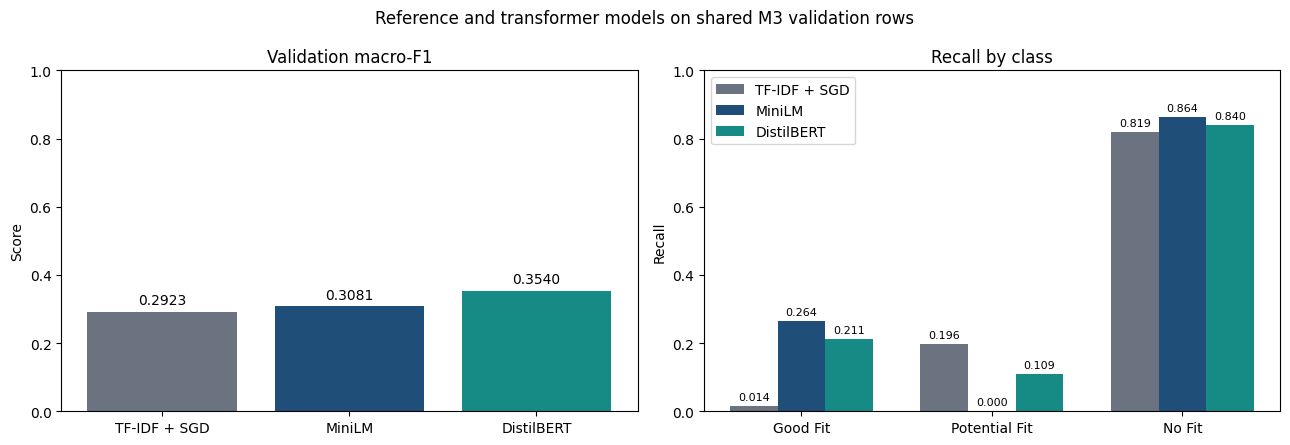

Figure saved to: /content/m4_reference/tfidf_sgd_v1/comparison/reference_model_comparison.png


In [18]:
import matplotlib.pyplot as plt

colors = ["#6B7280", "#1F4E79", "#168A84"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].bar(
    comparison_df["Model"],
    comparison_df["Validation macro-F1"],
    color=colors
)
axes[0].bar_label(bars, fmt="%.4f", padding=3)
axes[0].set_title("Validation macro-F1")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)

positions = np.arange(len(LABELS))
width = 0.25
recall_columns = ["Good Fit recall", "Potential Fit recall", "No Fit recall"]

for index, row in comparison_df.iterrows():
    bars = axes[1].bar(
        positions + (index - 1) * width,
        row[recall_columns].to_numpy(dtype=float),
        width=width,
        label=row["Model"],
        color=colors[index]
    )
    axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

axes[1].set_xticks(positions, LABELS)
axes[1].set_title("Recall by class")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.suptitle("Reference and transformer models on shared M3 validation rows")
fig.tight_layout()

figure_path = COMPARISON_DIR / "reference_model_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figure saved to:", figure_path)

In [19]:
scores = comparison_df.set_index("Model")

comparison_notes = f"""# Reference Model Evaluation

## Evaluation setup

The TF-IDF reference and both transformers use the same M3 source rows,
dataset revision, labels, and job-grouped validation split.
No jobs or prepared resume-job pairs overlap between splits.
Some resumes are shared, so this evaluates matching a largely known
candidate pool against unseen jobs.

TF-IDF retains its original baseline cleaning and uses full documents.
The transformers use their recorded preparation and 512-token truncation.
This compares complete approaches; it does not isolate architecture alone.

TF-IDF vocabulary and classifier fitting use training rows only.
The original baseline settings are retained without a validation search.

## Findings

- TF-IDF + SGD validation macro-F1: {scores.loc["TF-IDF + SGD", "Validation macro-F1"]:.4f}.
- MiniLM validation macro-F1: {scores.loc["MiniLM", "Validation macro-F1"]:.4f}.
- DistilBERT validation macro-F1: {scores.loc["DistilBERT", "Validation macro-F1"]:.4f}.
- DistilBERT's absolute gain over the reference: {scores.loc["DistilBERT", "Validation macro-F1"] - reference_f1:.4f}.
- TF-IDF identifies 4 of 280 Good Fit examples and 65 of 331 Potential Fit examples.
- TF-IDF has the highest Potential Fit recall among these runs.
- MiniLM has the highest Good Fit recall.
- DistilBERT leads on macro-F1 and accuracy.

## Limitations and next steps

These are single-seed validation results, not final test results.
All approaches miss many suitable candidates.
Historical M2 test scores use a different split and are not directly comparable.

The saved TF-IDF pipeline reproduces all 1,147 validation predictions.
It expects cleaned pair text, not raw resume and job fields.

Keep this run as the fixed reference for class-weighted training and
section-aware input experiments. Select settings using validation data.
Evaluate the official test set after model selection is fixed.
"""

notes_path = COMPARISON_DIR / "comparison_notes.md"
notes_path.write_text(comparison_notes, encoding="utf-8")

print("Comparison findings saved to:", notes_path)

Comparison findings saved to: /content/m4_reference/tfidf_sgd_v1/comparison/comparison_notes.md


In [20]:
saved_predictions = pd.read_csv(
    REPORT_DIR / "validation_predictions.csv"
)
saved_metrics = json.loads(
    (REPORT_DIR / "validation_metrics.json").read_text()
)
saved_confusion = pd.read_csv(
    REPORT_DIR / "validation_confusion_matrix.csv", index_col=0
)

np.testing.assert_array_equal(
    saved_predictions["source_row_id"],
    validation_df["source_row_id"]
)
np.testing.assert_array_equal(
    saved_predictions["true_label"],
    validation_df["label"]
)
np.testing.assert_array_equal(
    saved_predictions["predicted_label"],
    validation_predictions
)

recomputed_f1 = f1_score(
    saved_predictions["true_label"],
    saved_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_f1, saved_metrics["macro_f1"], rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_predictions["true_label"],
        saved_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(COMPARISON_DIR / "reference_model_comparison.csv"),
    comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert run_summary["official_test_evaluated"] is False
assert json.loads((REPORT_DIR / "reload_check.json").read_text())["passed"]

print("Saved predictions, source rows, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved predictions, source rows, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [21]:
from zipfile import ZIP_DEFLATED

reports_archive = Path("/content/tfidf_sgd_v1_reports.zip")
model_archive = Path("/content/tfidf_sgd_v1_model.zip")

with ZipFile(reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

with ZipFile(model_archive, "w", ZIP_DEFLATED) as archive:
    archive.write(model_path, model_path.name)
    archive.write(
        REPORT_DIR / "reference_config.json",
        "reference_config.json"
    )

for path in [reports_archive, model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(reports_archive))
files.download(str(model_archive))

tfidf_sgd_v1_reports.zip: 12 files, 0.12 MB
tfidf_sgd_v1_model.zip: 2 files, 1.35 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import sys
import subprocess
from importlib.metadata import version

packages = [
    "transformers==5.24.0",
    "huggingface-hub==1.33.0",
    "accelerate==1.15.0",
    "jedi==0.19.2"
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True
)
subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    check=True
)

for package in [
    "transformers", "huggingface-hub", "accelerate", "torch"
]:
    print(f"{package}: {version(package)}")

transformers: 5.24.0
huggingface-hub: 1.33.0
accelerate: 1.15.0
torch: 2.14.1+cu130


In [24]:
import random
import numpy as np
import torch
import transformers
import huggingface_hub

from transformers import set_seed

assert transformers.__version__ == "5.24.0"
assert huggingface_hub.__version__ == "1.33.0"
assert torch.cuda.is_available(), "Select a T4 GPU runtime in Colab."

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)

gpu = torch.cuda.get_device_properties(0)
splits_available = (
    "split_frames" in globals()
    and "split_manifest" in globals()
)

print("Transformers loaded:", transformers.__version__)
print("Hub loaded:", huggingface_hub.__version__)
print("GPU:", gpu.name)
print(f"GPU memory: {gpu.total_memory / 1024**3:.1f} GB")
print("Random seed:", SEED)
print("M3 splits available:", splits_available)

if splits_available:
    for name, frame in split_frames.items():
        print(f"{name}: {len(frame):,} rows")
else:
    print("We will restore the saved M3 splits next.")

Transformers loaded: 5.24.0
Hub loaded: 1.33.0
GPU: Tesla T4
GPU memory: 14.6 GB
Random seed: 42
M3 splits available: True
Training: 5,081 rows
Validation: 1,147 rows
Official test: 1,759 rows


In [25]:
from transformers import AutoTokenizer, AutoConfig

SECTION_MODEL_CHECKPOINT = "distilbert/distilbert-base-uncased"
SECTION_MODEL_REVISION = "12040accade4e8a0f71eabdb258fecc2e7e948be"
MAX_LENGTH = 512

section_tokenizer = AutoTokenizer.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION
)
section_model_config = AutoConfig.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION
)

assert section_model_config.model_type == "distilbert"
assert section_model_config.max_position_embeddings == MAX_LENGTH
assert split_manifest["seed"] == SEED
assert LABELS == ["Good Fit", "Potential Fit", "No Fit"]

for frame in split_frames.values():
    assert {"resume_model_text", "job_model_text"}.issubset(frame.columns)

print("Checkpoint:", SECTION_MODEL_CHECKPOINT)
print("Revision:", SECTION_MODEL_REVISION)
print("Input limit:", MAX_LENGTH)
print("Pair special tokens:", section_tokenizer.num_special_tokens_to_add(pair=True))
print("Tokenizer ready. Model weights have not been loaded.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Checkpoint: distilbert/distilbert-base-uncased
Revision: 12040accade4e8a0f71eabdb258fecc2e7e948be
Input limit: 512
Pair special tokens: 3
Tokenizer ready. Model weights have not been loaded.


In [26]:
import re

SECTION_PATTERNS = {
    "summary": r"(?:professional |career )?summary|profile|objective|about me",
    "skills": r"(?:(?:technical|core|key|professional) )?skills|core competencies",
    "experience": (
        r"(?:(?:work|professional|relevant|employment) )?experience"
        r"|employment history|work history"
    ),
    "projects": r"(?:(?:personal|academic|selected|relevant) )?projects",
    "education": r"education|academic background|educational qualifications",
    "certifications": r"certifications?|licenses?(?: and certifications?)?",
    "requirements": (
        r"(?:(?:minimum|preferred|required|basic|key) )?"
        r"(?:requirements|qualifications)|what you bring|what we look for"
    ),
    "responsibilities": (
        r"(?:(?:key|job|main) )?(?:responsibilities|duties)"
        r"|what you.ll do|your role"
    ),
    "overview": r"job description|job summary|job overview|about the role",
    "other": r"interests|hobbies|references|languages|benefits|about us"
}

SECTION_REGEX = {
    name: re.compile(
        rf"^(?:{pattern})\s*(?::\s*(?P<content>.*))?$",
        re.IGNORECASE
    )
    for name, pattern in SECTION_PATTERNS.items()
}


def parse_section_heading(line):
    candidate = re.sub(r"^\s*(?:#{1,6}\s*|[-*•]\s+)", "", line)
    candidate = candidate.replace("**", "").replace("__", "").strip()

    for name, pattern in SECTION_REGEX.items():
        match = pattern.fullmatch(candidate)
        if match:
            return name, (match.group("content") or "").strip()

    return None, ""


assert parse_section_heading("## Technical Skills")[0] == "skills"
assert parse_section_heading("**Requirements:** Python")[0] == "requirements"
assert parse_section_heading("Built a Python application")[0] is None

print("Section-heading detection is ready.")

Section-heading detection is ready.


In [27]:
from collections import Counter

coverage_rows = []
heading_counts = {}

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    counts = Counter()
    recognised_documents = 0

    for text in documents:
        headings = {
            section
            for line in text.splitlines()
            if (section := parse_section_heading(line)[0]) is not None
        }
        recognised_documents += bool(headings)
        counts.update(headings)

    heading_counts[document_type] = counts
    coverage_rows.append({
        "Document type": document_type,
        "Unique documents": len(documents),
        "With recognised headings": recognised_documents,
        "Coverage (%)": round(
            100 * recognised_documents / len(documents), 2
        )
    })

training_section_coverage = pd.DataFrame(coverage_rows)
training_heading_counts = (
    pd.DataFrame(heading_counts)
    .reindex(SECTION_PATTERNS)
    .fillna(0)
    .astype(int)
)
training_heading_counts.index.name = "Section"

display(training_section_coverage)
display(training_heading_counts)
print("Counts show documents containing each section, not heading occurrences.")

,Document type,Unique documents,With recognised headings,Coverage (%)
0,Resume,632,26,4.11
1,Job,229,109,47.60


,Resume,Job
Section,,
summary,0,2
skills,8,5
experience,0,3
projects,0,0
education,13,5
certifications,0,0
requirements,3,58
responsibilities,2,53
overview,0,35


Counts show documents containing each section, not heading occurrences.


In [29]:
heading_probe = re.compile(
    r"\b(?:summary|skills|experience|education|projects|"
    r"employment|qualifications|competencies|certifications?)\b",
    re.IGNORECASE
)

format_rows = []
heading_examples = []

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    line_counts = documents.map(lambda text: len(text.splitlines()))

    format_rows.append({
        "Document type": document_type,
        "Median lines": float(line_counts.median()),
        "Single-line documents (%)": round(
            100 * line_counts.eq(1).mean(), 2
        )
    })

    examples = set()
    for text in documents:
        for match in heading_probe.finditer(text):
            fragment = text[
                max(0, match.start() - 12):match.end() + 35
            ]
            examples.add(repr(fragment))
            if len(examples) >= 12:
                break
        if len(examples) >= 12:
            break

    heading_examples.extend({
        "Document type": document_type,
        "Heading fragment": fragment
    } for fragment in sorted(examples))

display(pd.DataFrame(format_rows))
display(pd.DataFrame(heading_examples))

,Document type,Median lines,Single-line documents (%)
0,Resume,5.0,0.00
1,Job,6.0,10.92


,Document type,Heading fragment
0,Resume,'NPI and CPI projects Provide technical for CA...
1,Resume,'are for NPI projects including 795FAC XQ (LMT...
2,Resume,'cerning CPI projects Incorporate best busines...
3,Resume,'e and sales experience. Outgoing sales profes...
4,Resume,'iance. this experience provided invaluable in...
5,Resume,"'lights-Soft Skills: Public Speaking, Public R..."
6,Resume,'n Christian Education - Dallas Theological Se...
7,Resume,'onstruction projects. Translates directives o...
8,Resume,'s Conducted projects on various job sites inv...
9,Resume,"'s:Christian Education,Expected in-Dallas Theo..."


In [30]:
SECTION_REGEX = {
    name: re.compile(
        rf"^(?i:{pattern})(?=$|[\s:|]|[A-Z0-9])"
        rf"[\s:|]*(?P<content>.*)$"
    )
    for name, pattern in SECTION_PATTERNS.items()
}


def parse_section_heading(line):
    candidate = re.sub(r"^\s*(?:#{1,6}\s*|[-*•]\s+)", "", line)
    candidate = candidate.replace("**", "").replace("__", "").strip()

    for name, pattern in SECTION_REGEX.items():
        match = pattern.fullmatch(candidate)
        if match:
            return name, match.group("content").strip()

    return None, ""


assert parse_section_heading("SkillsGuest services") == (
    "skills", "Guest services"
)
assert parse_section_heading("ExperienceCompany ABC")[0] == "experience"
assert parse_section_heading("Technical Skills: Python")[0] == "skills"
assert parse_section_heading("Experienced engineer")[0] is None

coverage_rows = []

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    recognised = sum(
        any(parse_section_heading(line)[0] is not None
            for line in text.splitlines())
        for text in documents
    )
    coverage_rows.append({
        "Document type": document_type,
        "Unique documents": len(documents),
        "With recognised headings": recognised,
        "Coverage (%)": round(100 * recognised / len(documents), 2)
    })

training_section_coverage = pd.DataFrame(coverage_rows)
display(training_section_coverage)

,Document type,Unique documents,With recognised headings,Coverage (%)
0,Resume,632,632,100.00
1,Job,229,156,68.12


In [31]:
def extract_sections(text):
    sections = {"preamble": []}
    current_section = "preamble"

    for line in text.splitlines():
        section_name, inline_content = parse_section_heading(line)

        if section_name is not None:
            current_section = section_name
            sections.setdefault(current_section, [])
            if inline_content:
                sections[current_section].append(inline_content)
        elif line.strip():
            sections.setdefault(current_section, []).append(line.strip())

    return {
        name: "\n".join(parts).strip()
        for name, parts in sections.items()
        if any(part.strip() for part in parts)
    }


example_sections = extract_sections(
    "Candidate profile\nSkillsPython, SQL\nExperienceBuilt data pipelines"
)
assert example_sections["skills"] == "Python, SQL"
assert example_sections["experience"] == "Built data pipelines"
assert extract_sections("Unstructured document") == {
    "preamble": "Unstructured document"
}

section_content_counts = {}

for document_type, text_column, group_column in [
    ("Resume", "resume_model_text", "resume_group"),
    ("Job", "job_model_text", "job_group")
]:
    documents = train_df.drop_duplicates(group_column)[text_column]
    counts = Counter()

    for text in documents:
        counts.update(extract_sections(text).keys())

    section_content_counts[document_type] = counts

training_section_content = (
    pd.DataFrame(section_content_counts)
    .reindex(["preamble", *SECTION_PATTERNS])
    .fillna(0)
    .astype(int)
)
training_section_content.index.name = "Non-empty section"

display(training_section_content)
print("Section extraction checks passed.")

,Resume,Job
Non-empty section,,
preamble,90,207
summary,549,5
skills,495,11
experience,628,22
projects,1,2
education,621,14
certifications,0,0
requirements,46,83
responsibilities,2,77


Section extraction checks passed.


In [32]:
SECTION_POLICY = {
    "name": "section_aware_v1",
    "max_length": MAX_LENGTH,
    "resume_budget": 304,
    "job_budget": 205,
    "add_section_labels": True,
    "resume_quotas": {
        "skills": 80,
        "experience": 128,
        "summary": 32,
        "education": 24,
        "projects": 24,
        "certifications": 16
    },
    "job_quotas": {
        "requirements": 112,
        "responsibilities": 64,
        "overview": 29
    },
    "resume_priority": [
        "skills", "experience", "summary", "education",
        "projects", "certifications", "preamble",
        "requirements", "responsibilities", "overview", "other"
    ],
    "job_priority": [
        "requirements", "responsibilities", "skills",
        "overview", "experience", "education", "preamble",
        "summary", "projects", "certifications", "other"
    ]
}

PAIR_SPECIAL_TOKENS = section_tokenizer.num_special_tokens_to_add(pair=True)

assert sum(SECTION_POLICY["resume_quotas"].values()) == 304
assert sum(SECTION_POLICY["job_quotas"].values()) == 205
assert 304 + 205 + PAIR_SPECIAL_TOKENS == MAX_LENGTH

for kind in ["resume", "job"]:
    assert set(SECTION_POLICY[f"{kind}_priority"]) == {
        "preamble", *SECTION_PATTERNS
    }

print("Policy:", SECTION_POLICY["name"])
print("Resume budget:", SECTION_POLICY["resume_budget"])
print("Job budget:", SECTION_POLICY["job_budget"])
print("Total limit including special tokens:", MAX_LENGTH)
print("Policy fixed before training or validation-based selection.")

Policy: section_aware_v1
Resume budget: 304
Job budget: 205
Total limit including special tokens: 512
Policy fixed before training or validation-based selection.


In [33]:
def encode_sections(text):
    sections = extract_sections(text)
    encoded = {}

    for name, content in sections.items():
        if SECTION_POLICY["add_section_labels"] and name != "preamble":
            content = f"{name.title()}: {content}"

        encoded[name] = section_tokenizer(
            content,
            add_special_tokens=False,
            truncation=False,
            verbose=False
        )["input_ids"]

    return encoded


def select_section_tokens(encoded_sections, document_type, budget):
    priority = SECTION_POLICY[f"{document_type}_priority"]
    quotas = SECTION_POLICY[f"{document_type}_quotas"]
    selected_counts = {name: 0 for name in encoded_sections}
    remaining = budget

    for name in priority:
        available = len(encoded_sections.get(name, []))
        take = min(available, quotas.get(name, 0), remaining)
        if name in selected_counts:
            selected_counts[name] = take
        remaining -= take

    for name in priority:
        available = len(encoded_sections.get(name, []))
        already_selected = selected_counts.get(name, 0)
        take = min(available - already_selected, remaining)
        if name in selected_counts:
            selected_counts[name] += take
        remaining -= take

    selected_ids = [
        token
        for name in priority
        for token in encoded_sections.get(name, [])[
            :selected_counts.get(name, 0)
        ]
    ]

    assert len(selected_ids) <= budget
    assert len(selected_ids) == sum(selected_counts.values())
    return selected_ids, selected_counts


sample_sections = encode_sections(
    "SkillsPython, SQL\nExperienceBuilt data pipelines"
)
sample_ids, sample_counts = select_section_tokens(
    sample_sections, "resume", SECTION_POLICY["resume_budget"]
)

assert sample_counts["skills"] > 0
assert sample_counts["experience"] > 0
assert len(sample_ids) == sum(map(len, sample_sections.values()))

print("Section encoding and token-selection checks passed.")
print("Short documents retain all extracted section content.")

Section encoding and token-selection checks passed.
Short documents retain all extracted section content.


In [34]:
def build_section_pair(resume_sections, job_sections):
    content_budget = MAX_LENGTH - PAIR_SPECIAL_TOKENS
    resume_available = sum(map(len, resume_sections.values()))
    job_available = sum(map(len, job_sections.values()))

    assert resume_available > 0 and job_available > 0

    resume_budget = min(
        SECTION_POLICY["resume_budget"], resume_available
    )
    job_budget = min(content_budget - resume_budget, job_available)
    resume_budget = min(content_budget - job_budget, resume_available)

    resume_ids, resume_counts = select_section_tokens(
        resume_sections, "resume", resume_budget
    )
    job_ids, job_counts = select_section_tokens(
        job_sections, "job", job_budget
    )

    input_ids = (
        [section_tokenizer.cls_token_id]
        + resume_ids
        + [section_tokenizer.sep_token_id]
        + job_ids
        + [section_tokenizer.sep_token_id]
    )

    assert len(input_ids) <= MAX_LENGTH
    assert len(input_ids) == len(resume_ids) + len(job_ids) + 3

    features = {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids)
    }
    allocation = {
        "resume": resume_counts,
        "job": job_counts
    }
    return features, allocation


probe_resume = section_tokenizer(
    "Python", add_special_tokens=False
)["input_ids"]
probe_job = section_tokenizer(
    "SQL", add_special_tokens=False
)["input_ids"]

assert section_tokenizer("Python", "SQL")["input_ids"] == (
    [section_tokenizer.cls_token_id] + probe_resume
    + [section_tokenizer.sep_token_id] + probe_job
    + [section_tokenizer.sep_token_id]
)

sample_features, sample_allocation = build_section_pair(
    sample_sections,
    encode_sections("RequirementsPython and SQL")
)

print("Pair construction matches the tokenizer's special-token format.")
print("Sample input length:", len(sample_features["input_ids"]))
print("Unused document space is reassigned within the 512-token limit.")

Pair construction matches the tokenizer's special-token format.
Sample input length: 19
Unused document space is reassigned within the 512-token limit.


In [35]:
from tqdm.auto import tqdm

SECTION_SPLITS = ["Training", "Validation"]
section_cache = {}

for document_type, text_column in [
    ("resume", "resume_model_text"),
    ("job", "job_model_text")
]:
    unique_texts = (
        pd.concat(
            [split_frames[name][text_column] for name in SECTION_SPLITS],
            ignore_index=True
        )
        .drop_duplicates()
        .tolist()
    )

    section_cache[document_type] = {
        text: encode_sections(text)
        for text in tqdm(
            unique_texts,
            desc=f"Encoding unique {document_type} documents"
        )
    }

    assert all(
        sum(map(len, sections.values())) > 0
        for sections in section_cache[document_type].values()
    )

    fallback_count = sum(
        set(sections) == {"preamble"}
        for sections in section_cache[document_type].values()
    )

    print(
        f"{document_type.title()}: {len(unique_texts):,} unique texts; "
        f"{fallback_count:,} use preamble-only fallback"
    )

print("Section cache ready. Official test documents were not processed.")

Encoding unique resume documents:   0%|          | 0/642 [00:00<?, ?it/s]

Resume: 642 unique texts; 0 use preamble-only fallback


Encoding unique job documents:   0%|          | 0/280 [00:00<?, ?it/s]

Job: 280 unique texts; 93 use preamble-only fallback
Section cache ready. Official test documents were not processed.


In [38]:
from datasets import Dataset, DatasetDict

section_datasets = DatasetDict()
allocation_rows = []

for split_name in SECTION_SPLITS:
    frame = split_frames[split_name]
    records = []

    for row in tqdm(
        frame.itertuples(index=False),
        total=len(frame),
        desc=f"Building {split_name}"
    ):
        features, allocation = build_section_pair(
            section_cache["resume"][row.resume_model_text],
            section_cache["job"][row.job_model_text]
        )
        features["labels"] = int(row.labels)
        records.append(features)

        audit = {
            "Split": split_name,
            "source_row_id": int(row.source_row_id),
            "input_tokens": len(features["input_ids"]),
            "resume_tokens": sum(allocation["resume"].values()),
            "job_tokens": sum(allocation["job"].values())
        }
        for document_type in ["resume", "job"]:
            for section_name in ["preamble", *SECTION_PATTERNS]:
                audit[f"{document_type}_{section_name}_tokens"] = (
                    allocation[document_type].get(section_name, 0)
                )
        allocation_rows.append(audit)

    section_datasets[split_name] = Dataset.from_list(records)

    np.testing.assert_array_equal(
        section_datasets[split_name]["labels"],
        frame["labels"].to_numpy()
    )
    assert len(section_datasets[split_name]) == len(frame)

section_allocation_report = pd.DataFrame(allocation_rows)

assert section_allocation_report["input_tokens"].le(MAX_LENGTH).all()
assert (
    section_allocation_report["resume_tokens"]
    + section_allocation_report["job_tokens"]
    + PAIR_SPECIAL_TOKENS
).equals(section_allocation_report["input_tokens"])

for name, data in section_datasets.items():
    print(name, len(data), data.column_names)

print("Section-aware datasets and allocation checks passed.")

Building Training:   0%|          | 0/5081 [00:00<?, ?it/s]

Building Validation:   0%|          | 0/1147 [00:00<?, ?it/s]

Training 5081 ['input_ids', 'attention_mask', 'labels']
Validation 1147 ['input_ids', 'attention_mask', 'labels']
Section-aware datasets and allocation checks passed.


In [40]:
section_length_summary = (
    section_allocation_report
    .groupby("Split", sort=False)
    .agg(
        Rows=("input_tokens", "size"),
        Minimum_tokens=("input_tokens", "min"),
        Maximum_tokens=("input_tokens", "max"),
        Mean_resume_tokens=("resume_tokens", "mean"),
        Mean_job_tokens=("job_tokens", "mean")
    )
)

section_token_columns = [
    f"{kind}_{section_name}_tokens"
    for kind, section_names in [
        ("resume", ["skills", "experience", "summary", "education", "projects"]),
        ("job", ["requirements", "responsibilities", "overview", "preamble"])
    ]
    for section_name in section_names
]

section_token_summary = (
    section_allocation_report
    .groupby("Split", sort=False)[section_token_columns]
    .mean()
    .T
)
section_token_summary.index.name = "Section token allocation"

assert section_allocation_report["resume_tokens"].gt(0).all()
assert section_allocation_report["job_tokens"].gt(0).all()

display(section_length_summary.round(2))
display(section_token_summary.round(2))
print("Token counts include section labels.")

,Rows,Minimum_tokens,Maximum_tokens,Mean_resume_tokens,Mean_job_tokens
Split,,,,,
Training,5081,331,512,316.40,192.44
Validation,1147,437,512,327.51,181.30


Split,Training,Validation
Section token allocation,,
resume_skills_tokens,77.72,76.47
resume_experience_tokens,185.40,197.46
resume_summary_tokens,28.73,28.88
resume_education_tokens,24.38,24.23
resume_projects_tokens,0.02,0.02
job_requirements_tokens,40.87,31.19
job_responsibilities_tokens,29.45,20.31
job_overview_tokens,27.54,14.02
job_preamble_tokens,83.06,101.73


Token counts include section labels.


In [41]:
from transformers import DataCollatorWithPadding

section_collator = DataCollatorWithPadding(
    tokenizer=section_tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

training_lengths = np.array([
    len(ids) for ids in section_datasets["Training"]["input_ids"]
])
sorted_indices = np.argsort(training_lengths)
batch_indices = [
    int(index)
    for index in np.concatenate([sorted_indices[:4], sorted_indices[-4:]])
]

section_check_batch = section_collator([
    section_datasets["Training"][index]
    for index in batch_indices
])

assert set(section_check_batch) == {
    "input_ids", "attention_mask", "labels"
}
assert section_check_batch["labels"].dtype == torch.int64
assert section_check_batch["input_ids"].shape == (8, MAX_LENGTH)

np.testing.assert_array_equal(
    section_check_batch["attention_mask"].sum(dim=1).numpy(),
    training_lengths[batch_indices]
)

print("Batch shapes:", {
    key: tuple(value.shape)
    for key, value in section_check_batch.items()
})
print(
    "Padding tokens:",
    int(section_check_batch["attention_mask"].eq(0).sum())
)
print("Label dtype:", section_check_batch["labels"].dtype)
print("Dynamic-padding checks passed.")

Batch shapes: {'input_ids': (8, 512), 'attention_mask': (8, 512), 'labels': (8,)}
Padding tokens: 485
Label dtype: torch.int64
Dynamic-padding checks passed.


In [42]:
import io
import json
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

baseline_archive_path = Path("/content/distilbert_v1_reports.zip")

if baseline_archive_path.exists():
    baseline_archive_bytes = baseline_archive_path.read_bytes()
    print("Reusing:", baseline_archive_path.name)
else:
    baseline_upload = files.upload()
    assert len(baseline_upload) == 1, "Upload distilbert_v1_reports.zip."
    baseline_archive_bytes = next(iter(baseline_upload.values()))

with ZipFile(io.BytesIO(baseline_archive_bytes)) as archive:
    original_distilbert_summary = json.loads(
        archive.read("run_summary.json")
    )
    original_distilbert_metrics = json.loads(
        archive.read("validation_metrics.json")
    )
    original_distilbert_arguments = json.loads(
        archive.read("training_arguments.json")
    )
    original_tokenization_config = json.loads(
        archive.read("tokenization_config.json")
    )

assert original_distilbert_summary["run_id"] == "distilbert_v1"
assert original_distilbert_summary["model_revision"] == SECTION_MODEL_REVISION
assert original_distilbert_summary["dataset_revision"] == (
    split_manifest["dataset_revision"]
)
assert original_distilbert_summary["seed"] == SEED
assert original_distilbert_summary["split_rows"] == {
    name: len(frame) for name, frame in split_frames.items()
}
assert original_tokenization_config["label2id"] == LABEL2ID
assert original_distilbert_summary["official_test_evaluated"] is False

print(
    "Original validation macro-F1:",
    round(original_distilbert_metrics["validation_macro_f1"], 4)
)
print("Original training settings loaded for the matched experiment.")

Reusing: distilbert_v1_reports.zip
Original validation macro-F1: 0.354
Original training settings loaded for the matched experiment.


In [43]:
from transformers import AutoModelForSequenceClassification

set_seed(SEED)
ID2LABEL = {index: label for label, index in LABEL2ID.items()}

section_model = AutoModelForSequenceClassification.from_pretrained(
    SECTION_MODEL_CHECKPOINT,
    revision=SECTION_MODEL_REVISION,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to("cuda")

assert section_model.config.label2id == LABEL2ID
assert all(parameter.requires_grad for parameter in section_model.parameters())

section_forward_batch = {
    key: value.to("cuda")
    for key, value in section_check_batch.items()
}

section_model.eval()
with torch.no_grad():
    section_diagnostic_output = section_model(**section_forward_batch)

assert section_diagnostic_output.logits.shape == (8, len(LABELS))
assert torch.isfinite(section_diagnostic_output.logits).all()
assert torch.isfinite(section_diagnostic_output.loss)

print("Checkpoint:", SECTION_MODEL_CHECKPOINT)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in section_model.parameters()):,}"
)
print("Logits shape:", tuple(section_diagnostic_output.logits.shape))
print(f"Diagnostic loss: {section_diagnostic_output.loss.item():.4f}")
print("Forward-pass checks passed. No weights were updated.")

del section_diagnostic_output, section_forward_batch

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: distilbert/distilbert-base-uncased
Trainable parameters: 66,955,779
Logits shape: (8, 3)
Diagnostic loss: 1.0835
Forward-pass checks passed. No weights were updated.


In [44]:
import math
from transformers import TrainingArguments

SECTION_OUTPUT_DIR = "/content/m4_training/distilbert_section_v1"

section_argument_values = original_distilbert_arguments.copy()
section_argument_values["output_dir"] = SECTION_OUTPUT_DIR

section_training_args = TrainingArguments(**section_argument_values)
resolved_section_arguments = section_training_args.to_dict()

for key, original_value in original_distilbert_arguments.items():
    if key != "output_dir":
        assert resolved_section_arguments[key] == original_value, key

effective_batch_size = (
    section_training_args.per_device_train_batch_size
    * section_training_args.gradient_accumulation_steps
)
updates_per_epoch = math.ceil(
    math.ceil(
        len(section_datasets["Training"])
        / section_training_args.per_device_train_batch_size
    )
    / section_training_args.gradient_accumulation_steps
)

print("Output directory:", SECTION_OUTPUT_DIR)
print("Maximum epochs:", section_training_args.num_train_epochs)
print("Learning rate:", section_training_args.learning_rate)
print("Effective batch size:", effective_batch_size)
print("Optimizer updates per epoch:", updates_per_epoch)
print("Warmup updates:", section_training_args.warmup_steps)
print("Checkpoint metric:", section_training_args.metric_for_best_model)
print("All saved training arguments match except the output directory.")

Output directory: /content/m4_training/distilbert_section_v1
Maximum epochs: 3
Learning rate: 2e-05
Effective batch size: 16
Optimizer updates per epoch: 318
Warmup updates: 96
Checkpoint metric: macro_f1
All saved training arguments match except the output directory.


In [45]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
from transformers import Trainer, EarlyStoppingCallback


def section_compute_metrics(evaluation):
    predictions = np.argmax(evaluation.predictions, axis=-1)
    true_labels = evaluation.label_ids
    label_ids = list(range(len(LABELS)))

    recalls = recall_score(
        true_labels, predictions,
        labels=label_ids, average=None, zero_division=0
    )

    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels, predictions,
            labels=label_ids, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            true_labels, predictions,
            labels=label_ids, average="weighted", zero_division=0
        ),
        "recall_good_fit": recalls[0],
        "recall_potential_fit": recalls[1],
        "recall_no_fit": recalls[2]
    }


set_seed(SEED)

section_trainer = Trainer(
    model=section_model,
    args=section_training_args,
    train_dataset=section_datasets["Training"],
    eval_dataset=section_datasets["Validation"],
    processing_class=section_tokenizer,
    data_collator=section_collator,
    compute_metrics=section_compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

assert section_trainer.state.global_step == 0
assert section_model.config.problem_type in {
    None, "single_label_classification"
}

print("Trainer ready.")
print("Loss: unweighted cross-entropy")
print("Early-stopping patience: 1")
print("Official test set is not passed to the trainer.")
print("Training has not started.")

Trainer ready.
Loss: unweighted cross-entropy
Early-stopping patience: 1
Official test set is not passed to the trainer.
Training has not started.


In [46]:
import time

assert section_trainer.state.global_step == 0, (
    "Training already started. Reinitialise the model and trainer "
    "before starting an independent run."
)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

section_training_started = time.perf_counter()
section_training_result = section_trainer.train()
torch.cuda.synchronize()

section_training_seconds = time.perf_counter() - section_training_started
section_peak_gpu_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Training wall time: {section_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {section_peak_gpu_gb:.2f} GB")
print("Optimizer updates:", section_trainer.state.global_step)
print(
    "Best validation macro-F1:",
    round(float(section_trainer.state.best_metric), 4)
)
print("Best checkpoint:", section_trainer.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,1.728621,1.066415,0.449869,0.295054,0.357127,0.175000,0.030211,0.852612
2,1.492845,1.236508,0.478640,0.325797,0.392467,0.050000,0.181269,0.886194
3,1.455226,1.397961,0.479512,0.317372,0.389125,0.035714,0.172205,0.901119


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 4.60 minutes
Peak GPU allocation: 1.95 GB
Optimizer updates: 954
Best validation macro-F1: 0.3258
Best checkpoint: /content/m4_training/distilbert_section_v1/checkpoint-636


In [47]:
from sklearn.metrics import classification_report, confusion_matrix

section_validation_output = section_trainer.predict(
    section_datasets["Validation"],
    metric_key_prefix="validation"
)

section_validation_predictions = np.argmax(
    section_validation_output.predictions, axis=-1
)
section_validation_labels = section_validation_output.label_ids

np.testing.assert_array_equal(
    section_validation_labels,
    validation_df["labels"].to_numpy()
)
np.testing.assert_allclose(
    section_validation_output.metrics["validation_macro_f1"],
    section_trainer.state.best_metric,
    rtol=1e-6
)

section_class_report = pd.DataFrame(
    classification_report(
        section_validation_labels,
        section_validation_predictions,
        labels=list(range(len(LABELS))),
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

section_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        section_validation_labels,
        section_validation_predictions,
        labels=list(range(len(LABELS)))
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(section_class_report.round(4))
display(section_confusion_matrix)
print(
    "Selected-checkpoint validation macro-F1:",
    round(section_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2456,0.0500,0.0831,280.0
Potential Fit,0.4348,0.1813,0.2559,331.0
No Fit,0.4989,0.8862,0.6384,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,14,32,234
Potential Fit,28,60,243
No Fit,15,46,475


Selected-checkpoint validation macro-F1: 0.3258


In [48]:
SECTION_RUN_DIR = Path(SECTION_OUTPUT_DIR)
SECTION_MODEL_DIR = SECTION_RUN_DIR / "best_model"
SECTION_REPORT_DIR = SECTION_RUN_DIR / "reports"
SECTION_REPORT_DIR.mkdir(parents=True, exist_ok=True)

section_trainer.save_model(str(SECTION_MODEL_DIR))
section_tokenizer.save_pretrained(str(SECTION_MODEL_DIR))

pd.DataFrame(section_trainer.state.log_history).to_csv(
    SECTION_REPORT_DIR / "training_history.csv", index=False
)
section_class_report.to_csv(
    SECTION_REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
section_confusion_matrix.to_csv(
    SECTION_REPORT_DIR / "validation_confusion_matrix.csv"
)
(SECTION_REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(section_validation_output.metrics, indent=2),
    encoding="utf-8"
)

section_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": [ID2LABEL[int(i)] for i in section_validation_labels],
    "predicted_label": [
        ID2LABEL[int(i)] for i in section_validation_predictions
    ]
})
section_prediction_report["correct"] = (
    section_prediction_report["true_label"]
    == section_prediction_report["predicted_label"]
)
section_prediction_report.to_csv(
    SECTION_REPORT_DIR / "validation_predictions.csv", index=False
)

print("Selected model saved to:", SECTION_MODEL_DIR)
for path in sorted(SECTION_REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m4_training/distilbert_section_v1/best_model
training_history.csv: 4,492 bytes
validation_class_report.csv: 247 bytes
validation_confusion_matrix.csv: 101 bytes
validation_metrics.json: 446 bytes
validation_predictions.csv: 31,936 bytes


In [49]:
section_input_config = {
    "run_id": "distilbert_section_v1",
    "dataset": split_manifest["dataset"],
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "model": SECTION_MODEL_CHECKPOINT,
    "model_revision": SECTION_MODEL_REVISION,
    "seed": SEED,
    "label2id": LABEL2ID,
    "policy": SECTION_POLICY,
    "heading_regex": {
        name: pattern.pattern
        for name, pattern in SECTION_REGEX.items()
    },
    "text_preparation": "Shared M3 prepare_text function",
    "heading_cleanup": "Remove leading Markdown heading/bullet and bold markers",
    "section_truncation": "Keep the prefix within each section allowance",
    "fallback": "Unrecognised lines remain in the current section or preamble",
    "pair_order": ["resume", "job"],
    "padding": "Dynamic, rounded to a multiple of 8",
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in [
            "transformers", "huggingface-hub", "tokenizers",
            "accelerate", "torch", "numpy", "pandas",
            "datasets", "scikit-learn"
        ]
    }
}

for filename, content in [
    ("section_input_config.json", section_input_config),
    ("training_arguments.json", section_training_args.to_dict())
]:
    (SECTION_REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print("Section-input configuration and training arguments saved.")

Section-input configuration and training arguments saved.


In [50]:
section_prediction_counts = np.bincount(
    section_validation_predictions, minlength=len(LABELS)
)

section_run_summary = {
    "run_id": "distilbert_section_v1",
    "model": SECTION_MODEL_CHECKPOINT,
    "model_revision": SECTION_MODEL_REVISION,
    "dataset_revision": split_manifest["dataset_revision"],
    "seed": SEED,
    "loss": "unweighted cross-entropy",
    "input_policy": SECTION_POLICY["name"],
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "epochs_run": float(section_trainer.state.epoch),
    "best_checkpoint": Path(
        section_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(section_trainer.state.best_metric),
    "optimizer_updates": section_trainer.state.global_step,
    "training_wall_seconds": section_training_seconds,
    "peak_gpu_allocated_gb": section_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int(section_prediction_counts[index])
        for index, label in enumerate(LABELS)
    },
    "official_test_processed_with_section_policy": False,
    "official_test_evaluated": False
}

(SECTION_REPORT_DIR / "run_summary.json").write_text(
    json.dumps(section_run_summary, indent=2), encoding="utf-8"
)

audit_reports = {
    "training_section_coverage.csv": (training_section_coverage, False),
    "training_section_content.csv": (training_section_content, True),
    "section_allocation.csv": (section_allocation_report, False),
    "section_length_summary.csv": (section_length_summary, True),
    "section_token_summary.csv": (section_token_summary, True)
}

for filename, (report, include_index) in audit_reports.items():
    report.to_csv(
        SECTION_REPORT_DIR / filename, index=include_index
    )

print(json.dumps(section_run_summary, indent=2))
print("Five section-audit reports saved.")

{
  "run_id": "distilbert_section_v1",
  "model": "distilbert/distilbert-base-uncased",
  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "unweighted cross-entropy",
  "input_policy": "section_aware_v1",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "epochs_run": 3.0,
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.32579681769104857,
  "optimizer_updates": 954,
  "training_wall_seconds": 275.7695493450001,
  "peak_gpu_allocated_gb": 1.9528608322143555,
  "validation_prediction_counts": {
    "Good Fit": 57,
    "Potential Fit": 138,
    "No Fit": 952
  },
  "official_test_processed_with_section_policy": false,
  "official_test_evaluated": false
}
Five section-audit reports saved.


In [51]:
section_reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(SECTION_MODEL_DIR), local_files_only=True
)
section_reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(SECTION_MODEL_DIR), local_files_only=True
).to("cuda")

original_state = section_trainer.model.state_dict()
reloaded_state = section_reloaded_model.state_dict()

assert original_state.keys() == reloaded_state.keys()

for name in original_state:
    assert torch.equal(
        original_state[name].detach().cpu(),
        reloaded_state[name].detach().cpu()
    ), name

assert section_reloaded_tokenizer.get_vocab() == (
    section_tokenizer.get_vocab()
)
assert section_reloaded_tokenizer.special_tokens_map == (
    section_tokenizer.special_tokens_map
)
assert section_reloaded_model.config.label2id == LABEL2ID
assert section_reloaded_model.config.id2label == ID2LABEL
assert json.loads(
    (SECTION_REPORT_DIR / "section_input_config.json").read_text()
) == section_input_config

print("Tensors checked:", len(original_state))
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer, labels, and section-input configuration also match.")

del original_state, reloaded_state

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tensors checked: 104
All saved weights and persistent buffers match exactly.
Tokenizer, labels, and section-input configuration also match.


In [52]:
section_reload_batch = {
    key: value.to("cuda")
    for key, value in section_collator([
        section_datasets["Validation"][index]
        for index in range(2)
    ]).items()
    if key != "labels"
}

section_trainer.model.eval()
section_reloaded_model.eval()

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
    original_logits = section_trainer.model(**section_reload_batch).logits.float()
    reloaded_logits = section_reloaded_model(**section_reload_batch).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

section_reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "section_input_config_matches": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(SECTION_REPORT_DIR / "reload_check.json").write_text(
    json.dumps(section_reload_check, indent=2), encoding="utf-8"
)

print(json.dumps(section_reload_check, indent=2))

del section_reloaded_model, section_reload_batch
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "section_input_config_matches": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


In [53]:
section_comparison_rows = []

for policy_name, metrics in [
    ("Original longest_first", original_distilbert_metrics),
    ("Section-aware v1", section_validation_output.metrics)
]:
    section_comparison_rows.append({
        "Input policy": policy_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

section_comparison_df = pd.DataFrame(section_comparison_rows)
SECTION_COMPARISON_DIR = SECTION_RUN_DIR / "comparison"
SECTION_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

section_comparison_df.to_csv(
    SECTION_COMPARISON_DIR / "input_policy_comparison.csv",
    index=False
)

section_macro_f1_change = (
    section_validation_output.metrics["validation_macro_f1"]
    - original_distilbert_metrics["validation_macro_f1"]
)

display(section_comparison_df.round(4))
print(f"Macro-F1 change: {section_macro_f1_change:+.4f}")
print("Original DistilBERT remains the stronger candidate by macro-F1.")
print("Official test set remains unevaluated.")

,Input policy,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,Original longest_first,0.3540,0.4752,0.2107,0.1088,0.8396
1,Section-aware v1,0.3258,0.4786,0.0500,0.1813,0.8862


Macro-F1 change: -0.0282
Original DistilBERT remains the stronger candidate by macro-F1.
Official test set remains unevaluated.


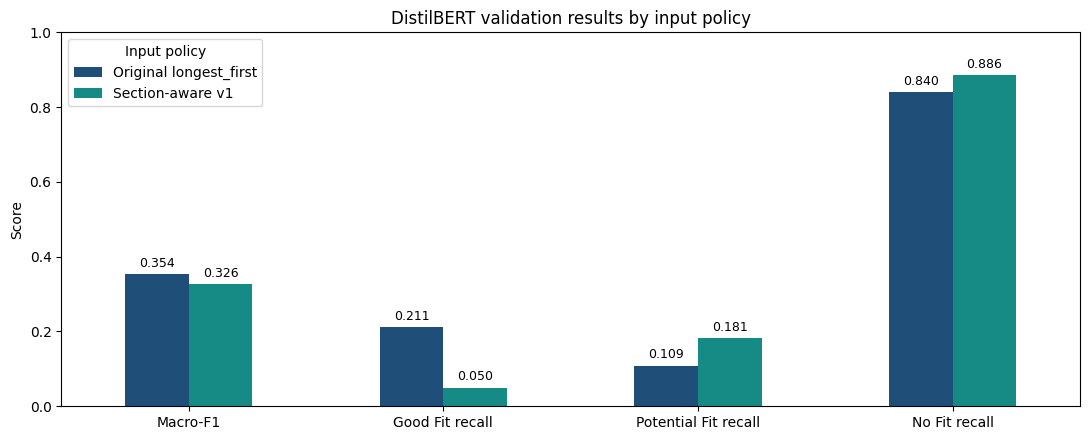

Figure saved to: /content/m4_training/distilbert_section_v1/comparison/input_policy_comparison.png


In [54]:
import matplotlib.pyplot as plt

plot_columns = [
    "Validation macro-F1",
    "Good Fit recall",
    "Potential Fit recall",
    "No Fit recall"
]

plot_data = section_comparison_df.set_index("Input policy")[plot_columns].T
plot_data.index = [
    "Macro-F1", "Good Fit recall", "Potential Fit recall", "No Fit recall"
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 4.5),
    color=["#1F4E79", "#168A84"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("DistilBERT validation results by input policy")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(title="Input policy")

figure = ax.get_figure()
figure.tight_layout()
figure_path = SECTION_COMPARISON_DIR / "input_policy_comparison.png"
figure.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)

print("Figure saved to:", figure_path)

In [55]:
section_comparison_notes = f"""# Section-Aware Input Evaluation

## Experiment setup

Both runs use the same DistilBERT checkpoint revision, M3 source rows,
labels, seed, unweighted loss, and saved training arguments.
Only the output directory differs in the training arguments.
Both runs select epoch 2 using validation macro-F1.

The new input policy detects sections, adds section labels, reorders content,
and allocates 304 resume tokens and 205 job tokens before reassigning unused
space. Three special tokens complete the 512-token limit.

## Results

- Original validation macro-F1: {original_distilbert_metrics["validation_macro_f1"]:.4f}.
- Section-aware validation macro-F1: {section_validation_output.metrics["validation_macro_f1"]:.4f}.
- Absolute macro-F1 change: {section_macro_f1_change:+.4f}.
- Good Fit recall falls from 0.2107 to 0.0500.
- Potential Fit recall rises from 0.1088 to 0.1813.
- No Fit recall rises from 0.8396 to 0.8862.
- Section-aware predictions include 57 Good Fit, 138 Potential Fit, and 952 No Fit.
- The model correctly identifies 14 of 280 Good Fit examples.

## Decision

Keep the original DistilBERT input policy as the stronger candidate.
The small accuracy increase does not offset lower macro-F1 and Good Fit recall.
Record this as an unsuccessful improvement iteration.

## Limitations

Heading detection was adjusted using training documents only.
Recognising headings does not establish correct section boundaries.
English heading rules may miss unusual layouts or interpret content as headings.

The policy changes section selection, ordering, labels, and token allocation
together. This experiment does not isolate their individual effects.
Reordering or discarding context could affect results, but no specific cause
has been established.

These are single-seed validation results. Section labels count toward the token
budget, so allocation counts are not measurements of original-content retention.
The official test set was neither processed with this policy nor evaluated.

Keep class-weighted training separate so its effect can be assessed against
the original input policy.
"""

notes_path = SECTION_COMPARISON_DIR / "comparison_notes.md"
notes_path.write_text(section_comparison_notes, encoding="utf-8")

print("Findings and decision saved to:", notes_path)

Findings and decision saved to: /content/m4_training/distilbert_section_v1/comparison/comparison_notes.md


In [56]:
saved_section_predictions = pd.read_csv(
    SECTION_REPORT_DIR / "validation_predictions.csv"
)
saved_section_metrics = json.loads(
    (SECTION_REPORT_DIR / "validation_metrics.json").read_text()
)
saved_section_confusion = pd.read_csv(
    SECTION_REPORT_DIR / "validation_confusion_matrix.csv",
    index_col=0
)

np.testing.assert_array_equal(
    saved_section_predictions["source_row_id"],
    validation_df["source_row_id"].to_numpy()
)
np.testing.assert_array_equal(
    saved_section_predictions["true_label"],
    validation_df["label"].to_numpy()
)

recomputed_section_f1 = f1_score(
    saved_section_predictions["true_label"],
    saved_section_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_section_f1,
    saved_section_metrics["validation_macro_f1"],
    rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_section_predictions["true_label"],
        saved_section_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_section_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(SECTION_COMPARISON_DIR / "input_policy_comparison.csv"),
    section_comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert json.loads(
    (SECTION_REPORT_DIR / "reload_check.json").read_text()
)["passed"]
assert section_run_summary["official_test_evaluated"] is False
assert section_run_summary["best_checkpoint"] == "checkpoint-636"

print("Saved source rows, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved source rows, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [57]:
from zipfile import ZIP_DEFLATED

section_reports_archive = Path(
    "/content/distilbert_section_v1_reports.zip"
)
section_model_archive = Path(
    "/content/distilbert_section_v1_model.zip"
)

with ZipFile(section_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(SECTION_REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(SECTION_COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(section_model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in model_files:
        path = SECTION_MODEL_DIR / filename
        assert path.exists(), filename
        archive.write(path, filename)

    archive.write(
        SECTION_REPORT_DIR / "section_input_config.json",
        "section_input_config.json"
    )

for path in [section_reports_archive, section_model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(section_reports_archive))
files.download(str(section_model_archive))

distilbert_section_v1_reports.zip: 17 files, 0.15 MB
distilbert_section_v1_model.zip: 5 files, 235.75 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
WEIGHTED_OUTPUT_DIR = "/content/m4_training/distilbert_weighted_v1"

training_label_ids = train_df["labels"].to_numpy()
training_class_counts = np.bincount(
    training_label_ids, minlength=len(LABELS)
)

assert len(training_label_ids) == 5081
assert (training_class_counts > 0).all()
assert LABELS == ["Good Fit", "Potential Fit", "No Fit"]

class_weight_values = (
    len(training_label_ids)
    / (len(LABELS) * training_class_counts)
)
CLASS_WEIGHTS = torch.tensor(
    class_weight_values, dtype=torch.float32
)

class_weight_report = pd.DataFrame({
    "Label": LABELS,
    "Training examples": training_class_counts,
    "Class weight": class_weight_values
})

display(class_weight_report.round(4))
print("Formula: training rows / (number of classes × class count)")
print("Validation and test labels were not used to calculate weights.")
print("Training has not started.")

,Label,Training examples,Class weight
0,Good Fit,1258,1.3463
1,Potential Fit,1223,1.3848
2,No Fit,2600,0.6514


Formula: training rows / (number of classes × class count)
Validation and test labels were not used to calculate weights.
Training has not started.


In [59]:
weighted_tokenizer = section_tokenizer

assert weighted_tokenizer.truncation_side == "right"
assert original_distilbert_summary["model_revision"] == SECTION_MODEL_REVISION

WEIGHTED_MAX_LENGTH = 512


def tokenize_original_pairs(batch):
    return weighted_tokenizer(
        batch["resume_model_text"],
        batch["job_model_text"],
        add_special_tokens=True,
        truncation="longest_first",
        max_length=WEIGHTED_MAX_LENGTH,
        padding=False,
        return_token_type_ids=False,
        return_attention_mask=True
    )


weighted_datasets = DatasetDict()

for split_name in ["Training", "Validation"]:
    frame = split_frames[split_name]
    source_data = Dataset.from_pandas(
        frame[["resume_model_text", "job_model_text", "labels"]],
        preserve_index=False
    )

    weighted_datasets[split_name] = source_data.map(
        tokenize_original_pairs,
        batched=True,
        remove_columns=["resume_model_text", "job_model_text"],
        desc=f"Original inputs: {split_name}"
    )

    np.testing.assert_array_equal(
        weighted_datasets[split_name]["labels"],
        frame["labels"].to_numpy()
    )
    assert all(
        0 < len(ids) <= WEIGHTED_MAX_LENGTH
        for ids in weighted_datasets[split_name]["input_ids"]
    )

    print(
        split_name,
        len(weighted_datasets[split_name]),
        weighted_datasets[split_name].column_names
    )

print("Original input policy restored. No section selection is applied.")

Original inputs: Training:   0%|          | 0/5081 [00:00<?, ? examples/s]

Training 5081 ['labels', 'input_ids', 'attention_mask']


Original inputs: Validation:   0%|          | 0/1147 [00:00<?, ? examples/s]

Validation 1147 ['labels', 'input_ids', 'attention_mask']
Original input policy restored. No section selection is applied.


In [60]:
weighted_collator = DataCollatorWithPadding(
    tokenizer=weighted_tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

weighted_length_rows = []

for split_name, data in weighted_datasets.items():
    lengths = np.array([len(ids) for ids in data["input_ids"]])
    weighted_length_rows.append({
        "Split": split_name,
        "Rows": len(data),
        "Minimum tokens": int(lengths.min()),
        "Maximum tokens": int(lengths.max()),
        "Mean tokens": float(lengths.mean())
    })

weighted_input_report = pd.DataFrame(weighted_length_rows)

training_lengths = np.array([
    len(ids) for ids in weighted_datasets["Training"]["input_ids"]
])
ordered_indices = np.argsort(training_lengths)
weighted_batch_indices = [
    int(index)
    for index in np.concatenate([ordered_indices[:4], ordered_indices[-4:]])
]

weighted_check_batch = weighted_collator([
    weighted_datasets["Training"][index]
    for index in weighted_batch_indices
])

assert set(weighted_check_batch) == {"input_ids", "attention_mask", "labels"}
assert weighted_check_batch["labels"].dtype == torch.int64
assert weighted_check_batch["input_ids"].shape == (8, 512)

np.testing.assert_array_equal(
    weighted_check_batch["attention_mask"].sum(dim=1).numpy(),
    training_lengths[weighted_batch_indices]
)

display(weighted_input_report.round(2))
print("Batch shape:", tuple(weighted_check_batch["input_ids"].shape))
print("Padding tokens:", int(weighted_check_batch["attention_mask"].eq(0).sum()))
print("Original-input batch checks passed.")

,Split,Rows,Minimum tokens,Maximum tokens,Mean tokens
0,Training,5081,334,512,511.85
1,Validation,1147,437,512,511.83


Batch shape: (8, 512)
Padding tokens: 475
Original-input batch checks passed.


In [61]:
section_trainer.model.to("cpu")

if section_trainer.optimizer is not None:
    for state in section_trainer.optimizer.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value):
                state[key] = value.cpu()

torch.cuda.empty_cache()
set_seed(SEED)

WEIGHTED_MODEL_CHECKPOINT = original_distilbert_summary["model"]
WEIGHTED_MODEL_REVISION = original_distilbert_summary["model_revision"]

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    WEIGHTED_MODEL_CHECKPOINT,
    revision=WEIGHTED_MODEL_REVISION,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to("cuda")

assert weighted_model.config.label2id == LABEL2ID
assert all(parameter.requires_grad for parameter in weighted_model.parameters())

print("Section-aware model device:", next(section_trainer.model.parameters()).device)
print("New model device:", next(weighted_model.parameters()).device)
print("Checkpoint:", WEIGHTED_MODEL_CHECKPOINT)
print(
    "Trainable parameters:",
    f"{sum(parameter.numel() for parameter in weighted_model.parameters()):,}"
)
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print("Fresh model loaded. No training has started.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Section-aware model device: cpu
New model device: cuda:0
Checkpoint: distilbert/distilbert-base-uncased
Trainable parameters: 66,955,779
GPU memory allocated: 0.27 GB
Fresh model loaded. No training has started.


In [62]:
import torch.nn.functional as F


class ClassWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights.detach().clone()
        self.model_accepts_loss_kwargs = False

    def compute_loss(
        self, model, inputs, return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs["labels"]
        model_inputs = {
            key: value for key, value in inputs.items()
            if key != "labels"
        }
        outputs = model(**model_inputs)
        logits = outputs.logits.float()

        loss = F.cross_entropy(
            logits,
            labels,
            weight=self.class_weights.to(logits.device),
            reduction="mean"
        )
        return (loss, outputs) if return_outputs else loss


probe_logits = torch.tensor([
    [2.0, 0.5, -0.5],
    [0.2, 1.0, 0.4],
    [0.8, 0.1, 1.2]
])
probe_labels = torch.tensor([0, 1, 2])

probe_loss = F.cross_entropy(
    probe_logits, probe_labels, weight=CLASS_WEIGHTS
)
per_example_loss = -F.log_softmax(probe_logits, dim=-1)[
    torch.arange(len(probe_labels)), probe_labels
]
example_weights = CLASS_WEIGHTS[probe_labels]
manual_loss = (
    (per_example_loss * example_weights).sum()
    / example_weights.sum()
)

torch.testing.assert_close(probe_loss, manual_loss)

print(f"Weighted loss: {probe_loss.item():.6f}")
print(f"Manual verification: {manual_loss.item():.6f}")
print("Weighted-loss calculation passed. No model weights were updated.")

Weighted loss: 0.523209
Manual verification: 0.523209
Weighted-loss calculation passed. No model weights were updated.


In [63]:
weighted_argument_values = original_distilbert_arguments.copy()
weighted_argument_values["output_dir"] = WEIGHTED_OUTPUT_DIR

weighted_training_args = TrainingArguments(**weighted_argument_values)
resolved_weighted_arguments = weighted_training_args.to_dict()

for key, original_value in original_distilbert_arguments.items():
    if key != "output_dir":
        assert resolved_weighted_arguments[key] == original_value, key

set_seed(SEED)

weighted_trainer = ClassWeightedTrainer(
    model=weighted_model,
    args=weighted_training_args,
    train_dataset=weighted_datasets["Training"],
    eval_dataset=weighted_datasets["Validation"],
    processing_class=weighted_tokenizer,
    data_collator=weighted_collator,
    compute_metrics=section_compute_metrics,
    class_weights=CLASS_WEIGHTS,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

assert weighted_trainer.state.global_step == 0
assert weighted_trainer.model_accepts_loss_kwargs is False
torch.testing.assert_close(
    weighted_trainer.class_weights.cpu(), CLASS_WEIGHTS.cpu()
)

print("Output directory:", WEIGHTED_OUTPUT_DIR)
print("Maximum epochs:", weighted_training_args.num_train_epochs)
print("Learning rate:", weighted_training_args.learning_rate)
print("Input policy: original longest_first, 512 tokens")
print("Loss: class-weighted cross-entropy")
print("Training arguments match the original except the output directory.")
print("Trainer ready. Training has not started.")

Output directory: /content/m4_training/distilbert_weighted_v1
Maximum epochs: 3
Learning rate: 2e-05
Input policy: original longest_first, 512 tokens
Loss: class-weighted cross-entropy
Training arguments match the original except the output directory.
Trainer ready. Training has not started.


In [64]:
assert weighted_trainer.state.global_step == 0, (
    "Training already started. Reinitialise the model and trainer "
    "before starting an independent run."
)

diagnostic_batch = {
    key: value.to("cuda")
    for key, value in weighted_check_batch.items()
}

weighted_trainer.model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    diagnostic_loss, diagnostic_output = weighted_trainer.compute_loss(
        weighted_trainer.model,
        diagnostic_batch,
        return_outputs=True
    )

assert diagnostic_output.logits.shape == (8, len(LABELS))
assert torch.isfinite(diagnostic_output.logits).all()
assert torch.isfinite(diagnostic_loss)
print(f"Initial weighted diagnostic loss: {diagnostic_loss.item():.4f}")

del diagnostic_batch, diagnostic_loss, diagnostic_output
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

weighted_training_started = time.perf_counter()
weighted_training_result = weighted_trainer.train()
torch.cuda.synchronize()

weighted_training_seconds = time.perf_counter() - weighted_training_started
weighted_peak_gpu_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Training wall time: {weighted_training_seconds / 60:.2f} minutes")
print(f"Peak GPU allocation: {weighted_peak_gpu_gb:.2f} GB")
print("Optimizer updates:", weighted_trainer.state.global_step)
print(
    "Best validation macro-F1:",
    round(float(weighted_trainer.state.best_metric), 4)
)
print("Best checkpoint:", weighted_trainer.state.best_model_checkpoint)

Initial weighted diagnostic loss: 1.0895


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Recall Good Fit,Recall Potential Fit,Recall No Fit
1,0.840030,1.303762,0.292938,0.280815,0.281202,0.217857,0.537764,0.180970
2,0.757417,1.319518,0.467306,0.358204,0.414933,0.167857,0.166163,0.809701
3,0.765029,1.444613,0.460331,0.343060,0.402683,0.146429,0.148036,0.817164


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training wall time: 5.12 minutes
Peak GPU allocation: 1.95 GB
Optimizer updates: 954
Best validation macro-F1: 0.3582
Best checkpoint: /content/m4_training/distilbert_weighted_v1/checkpoint-636


In [65]:
weighted_validation_output = weighted_trainer.predict(
    weighted_datasets["Validation"],
    metric_key_prefix="validation"
)

weighted_validation_predictions = np.argmax(
    weighted_validation_output.predictions, axis=-1
)
weighted_validation_labels = weighted_validation_output.label_ids

np.testing.assert_array_equal(
    weighted_validation_labels,
    validation_df["labels"].to_numpy()
)
np.testing.assert_allclose(
    weighted_validation_output.metrics["validation_macro_f1"],
    weighted_trainer.state.best_metric,
    rtol=1e-6
)

weighted_class_report = pd.DataFrame(
    classification_report(
        weighted_validation_labels,
        weighted_validation_predictions,
        labels=list(range(len(LABELS))),
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

weighted_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        weighted_validation_labels,
        weighted_validation_predictions,
        labels=list(range(len(LABELS)))
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

display(weighted_class_report.round(4))
display(weighted_confusion_matrix)
print(
    "Selected-checkpoint validation macro-F1:",
    round(weighted_validation_output.metrics["validation_macro_f1"], 4)
)

,precision,recall,f1-score,support
Good Fit,0.2938,0.1679,0.2136,280.0
Potential Fit,0.3313,0.1662,0.2213,331.0
No Fit,0.5286,0.8097,0.6396,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,47,57,176
Potential Fit,65,55,211
No Fit,48,54,434


Selected-checkpoint validation macro-F1: 0.3582


In [66]:
WEIGHTED_RUN_DIR = Path(WEIGHTED_OUTPUT_DIR)
WEIGHTED_MODEL_DIR = WEIGHTED_RUN_DIR / "best_model"
WEIGHTED_REPORT_DIR = WEIGHTED_RUN_DIR / "reports"
WEIGHTED_REPORT_DIR.mkdir(parents=True, exist_ok=True)

weighted_trainer.save_model(str(WEIGHTED_MODEL_DIR))
weighted_tokenizer.save_pretrained(str(WEIGHTED_MODEL_DIR))

pd.DataFrame(weighted_trainer.state.log_history).to_csv(
    WEIGHTED_REPORT_DIR / "training_history.csv", index=False
)
weighted_class_report.to_csv(
    WEIGHTED_REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
weighted_confusion_matrix.to_csv(
    WEIGHTED_REPORT_DIR / "validation_confusion_matrix.csv"
)
(WEIGHTED_REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(weighted_validation_output.metrics, indent=2),
    encoding="utf-8"
)

weighted_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": [ID2LABEL[int(i)] for i in weighted_validation_labels],
    "predicted_label": [
        ID2LABEL[int(i)] for i in weighted_validation_predictions
    ]
})
weighted_prediction_report["correct"] = (
    weighted_prediction_report["true_label"]
    == weighted_prediction_report["predicted_label"]
)
weighted_prediction_report.to_csv(
    WEIGHTED_REPORT_DIR / "validation_predictions.csv", index=False
)

print("Selected model saved to:", WEIGHTED_MODEL_DIR)
for path in sorted(WEIGHTED_REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Selected model saved to: /content/m4_training/distilbert_weighted_v1/best_model
training_history.csv: 4,586 bytes
validation_class_report.csv: 251 bytes
validation_confusion_matrix.csv: 101 bytes
validation_metrics.json: 457 bytes
validation_predictions.csv: 32,351 bytes


In [67]:
weighted_run_config = {
    "run_id": "distilbert_weighted_v1",
    "dataset": split_manifest["dataset"],
    "dataset_revision": split_manifest["dataset_revision"],
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "model": WEIGHTED_MODEL_CHECKPOINT,
    "model_revision": WEIGHTED_MODEL_REVISION,
    "seed": SEED,
    "label2id": LABEL2ID,
    "class_weight_formula": "training_rows / (number_of_classes * class_count)",
    "training_class_counts": dict(zip(
        LABELS, training_class_counts.astype(int).tolist()
    )),
    "class_weights": dict(zip(LABELS, CLASS_WEIGHTS.tolist())),
    "loss": "Class-weighted cross-entropy",
    "loss_reduction": "Weighted mean within each microbatch",
    "model_accepts_loss_kwargs": False,
    "input_policy": {
        "text_preparation": "Shared M3 prepare_text; no section selection",
        "pair_order": ["resume", "job"],
        "max_length": WEIGHTED_MAX_LENGTH,
        "truncation": "longest_first",
        "truncation_side": weighted_tokenizer.truncation_side,
        "padding": "Dynamic, rounded to a multiple of 8"
    },
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in [
            "transformers", "huggingface-hub", "tokenizers",
            "accelerate", "torch", "numpy", "pandas",
            "datasets", "scikit-learn"
        ]
    }
}

for filename, content in [
    ("weighted_run_config.json", weighted_run_config),
    ("training_arguments.json", weighted_training_args.to_dict())
]:
    (WEIGHTED_REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

class_weight_report.to_csv(
    WEIGHTED_REPORT_DIR / "class_weights.csv", index=False
)
weighted_input_report.to_csv(
    WEIGHTED_REPORT_DIR / "input_lengths.csv", index=False
)

print("Run configuration, training arguments, weights, and input audit saved.")

Run configuration, training arguments, weights, and input audit saved.


In [68]:
weighted_prediction_counts = np.bincount(
    weighted_validation_predictions, minlength=len(LABELS)
)

weighted_run_summary = {
    "run_id": "distilbert_weighted_v1",
    "model": WEIGHTED_MODEL_CHECKPOINT,
    "model_revision": WEIGHTED_MODEL_REVISION,
    "dataset_revision": split_manifest["dataset_revision"],
    "seed": SEED,
    "loss": "class-weighted cross-entropy",
    "input_policy": "original_longest_first",
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "epochs_run": float(weighted_trainer.state.epoch),
    "best_checkpoint": Path(
        weighted_trainer.state.best_model_checkpoint
    ).name,
    "best_validation_macro_f1": float(weighted_trainer.state.best_metric),
    "optimizer_updates": weighted_trainer.state.global_step,
    "training_wall_seconds": weighted_training_seconds,
    "peak_gpu_allocated_gb": weighted_peak_gpu_gb,
    "validation_prediction_counts": {
        label: int(weighted_prediction_counts[index])
        for index, label in enumerate(LABELS)
    },
    "class_weights_from_training_only": True,
    "official_test_evaluated": False
}

(WEIGHTED_REPORT_DIR / "run_summary.json").write_text(
    json.dumps(weighted_run_summary, indent=2), encoding="utf-8"
)

print(json.dumps(weighted_run_summary, indent=2))

{
  "run_id": "distilbert_weighted_v1",
  "model": "distilbert/distilbert-base-uncased",
  "model_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
  "dataset_revision": "08978e21714984bb417547d2c0f9b477f5298163",
  "seed": 42,
  "loss": "class-weighted cross-entropy",
  "input_policy": "original_longest_first",
  "split_rows": {
    "Training": 5081,
    "Validation": 1147,
    "Official test": 1759
  },
  "epochs_run": 3.0,
  "best_checkpoint": "checkpoint-636",
  "best_validation_macro_f1": 0.35820353666628063,
  "optimizer_updates": 954,
  "training_wall_seconds": 307.41885549200015,
  "peak_gpu_allocated_gb": 1.94504976272583,
  "validation_prediction_counts": {
    "Good Fit": 160,
    "Potential Fit": 166,
    "No Fit": 821
  },
  "class_weights_from_training_only": true,
  "official_test_evaluated": false
}


In [69]:
weighted_reloaded_tokenizer = AutoTokenizer.from_pretrained(
    str(WEIGHTED_MODEL_DIR), local_files_only=True
)
weighted_reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    str(WEIGHTED_MODEL_DIR), local_files_only=True
).to("cuda")

weighted_original_state = weighted_trainer.model.state_dict()
weighted_saved_state = weighted_reloaded_model.state_dict()

assert weighted_original_state.keys() == weighted_saved_state.keys()

for name in weighted_original_state:
    assert torch.equal(
        weighted_original_state[name].detach().cpu(),
        weighted_saved_state[name].detach().cpu()
    ), name

assert weighted_reloaded_tokenizer.get_vocab() == (
    weighted_tokenizer.get_vocab()
)
assert weighted_reloaded_tokenizer.special_tokens_map == (
    weighted_tokenizer.special_tokens_map
)
assert weighted_reloaded_model.config.label2id == LABEL2ID
assert weighted_reloaded_model.config.id2label == ID2LABEL
assert json.loads(
    (WEIGHTED_REPORT_DIR / "weighted_run_config.json").read_text()
) == weighted_run_config

print("Tensors checked:", len(weighted_original_state))
print("All saved weights and persistent buffers match exactly.")
print("Tokenizer, labels, and weighted-run configuration also match.")

del weighted_original_state, weighted_saved_state

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tensors checked: 104
All saved weights and persistent buffers match exactly.
Tokenizer, labels, and weighted-run configuration also match.


In [70]:
weighted_reload_batch = {
    key: value.to("cuda")
    for key, value in weighted_collator([
        weighted_datasets["Validation"][index]
        for index in range(2)
    ]).items()
    if key != "labels"
}

weighted_trainer.model.eval()
weighted_reloaded_model.eval()

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
    original_logits = weighted_trainer.model(**weighted_reload_batch).logits.float()
    reloaded_logits = weighted_reloaded_model(**weighted_reload_batch).logits.float()

torch.testing.assert_close(
    original_logits, reloaded_logits, rtol=1e-4, atol=1e-5
)
assert torch.equal(
    original_logits.argmax(dim=-1),
    reloaded_logits.argmax(dim=-1)
)

weighted_reload_check = {
    "weights_match_exactly": True,
    "tokenizer_and_labels_match": True,
    "weighted_run_config_matches": True,
    "comparison_precision": "FP16 autocast",
    "validation_examples_checked": 2,
    "maximum_logit_difference": float(
        (original_logits - reloaded_logits).abs().max().item()
    ),
    "passed": True
}

(WEIGHTED_REPORT_DIR / "reload_check.json").write_text(
    json.dumps(weighted_reload_check, indent=2), encoding="utf-8"
)

print(json.dumps(weighted_reload_check, indent=2))

del weighted_reloaded_model, weighted_reload_batch
del original_logits, reloaded_logits
torch.cuda.empty_cache()

{
  "weights_match_exactly": true,
  "tokenizer_and_labels_match": true,
  "weighted_run_config_matches": true,
  "comparison_precision": "FP16 autocast",
  "validation_examples_checked": 2,
  "maximum_logit_difference": 0.0,
  "passed": true
}


In [71]:
weighted_comparison_rows = []

for loss_name, metrics in [
    ("Unweighted cross-entropy", original_distilbert_metrics),
    ("Class-weighted cross-entropy", weighted_validation_output.metrics)
]:
    weighted_comparison_rows.append({
        "Loss": loss_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

weighted_comparison_df = pd.DataFrame(weighted_comparison_rows)
WEIGHTED_COMPARISON_DIR = WEIGHTED_RUN_DIR / "comparison"
WEIGHTED_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

weighted_comparison_df.to_csv(
    WEIGHTED_COMPARISON_DIR / "loss_comparison.csv",
    index=False
)

weighted_macro_f1_change = (
    weighted_validation_output.metrics["validation_macro_f1"]
    - original_distilbert_metrics["validation_macro_f1"]
)

display(weighted_comparison_df.round(4))
print(f"Macro-F1 change: {weighted_macro_f1_change:+.4f}")
print("This is a small single-seed validation gain.")
print("Official test set remains unevaluated.")

,Loss,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,Unweighted cross-entropy,0.3540,0.4752,0.2107,0.1088,0.8396
1,Class-weighted cross-entropy,0.3582,0.4673,0.1679,0.1662,0.8097


Macro-F1 change: +0.0042
This is a small single-seed validation gain.
Official test set remains unevaluated.


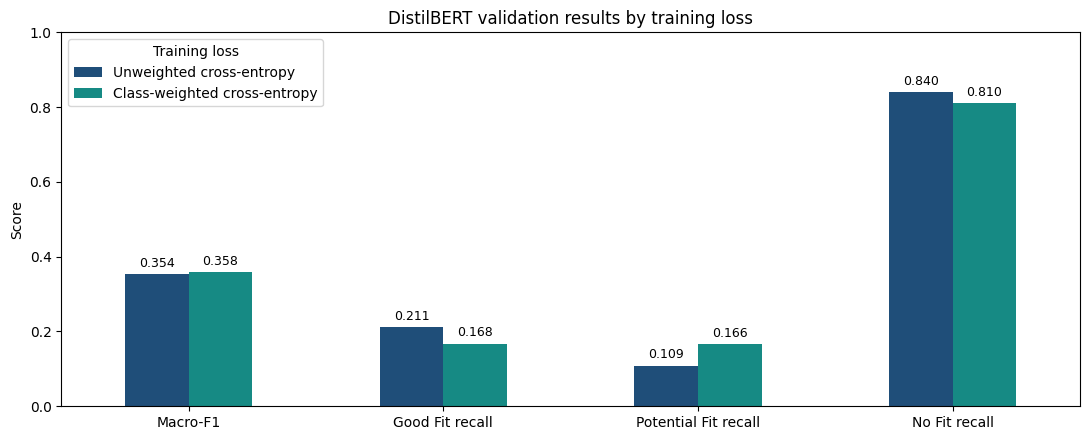

Figure saved to: /content/m4_training/distilbert_weighted_v1/comparison/loss_comparison.png


In [72]:
plot_columns = [
    "Validation macro-F1",
    "Good Fit recall",
    "Potential Fit recall",
    "No Fit recall"
]

weighted_plot_data = weighted_comparison_df.set_index("Loss")[plot_columns].T
weighted_plot_data.index = [
    "Macro-F1", "Good Fit recall", "Potential Fit recall", "No Fit recall"
]

ax = weighted_plot_data.plot(
    kind="bar",
    figsize=(11, 4.5),
    color=["#1F4E79", "#168A84"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("DistilBERT validation results by training loss")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(title="Training loss")

figure = ax.get_figure()
figure.tight_layout()
weighted_figure_path = WEIGHTED_COMPARISON_DIR / "loss_comparison.png"
figure.savefig(weighted_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(figure)

print("Figure saved to:", weighted_figure_path)

In [73]:
weighted_comparison_notes = f"""# Class-Weighted DistilBERT Evaluation

## Experiment setup

Both runs start from the same pretrained DistilBERT checkpoint revision.
They use the same M3 source rows, labels, seed, original longest_first inputs,
512-token limit, and saved training arguments except the output directory.
No section-aware preparation is applied.

Class weights are calculated from training labels only:
training_rows / (number_of_classes * class_count).

The custom trainer computes weighted-mean cross-entropy within each microbatch.
It sets model_accepts_loss_kwargs=False so Trainer handles gradient accumulation.
Both runs select epoch 2 using validation macro-F1.

## Results

- Original validation macro-F1: {original_distilbert_metrics["validation_macro_f1"]:.4f}.
- Weighted validation macro-F1: {weighted_validation_output.metrics["validation_macro_f1"]:.4f}.
- Absolute macro-F1 change: {weighted_macro_f1_change:+.4f}.
- Accuracy falls from 0.4752 to 0.4673.
- Good Fit recall falls from 0.2107 to 0.1679.
- Potential Fit recall rises from 0.1088 to 0.1662.
- No Fit recall falls from 0.8396 to 0.8097.

The weighted model correctly identifies 47 Good Fit, 55 Potential Fit,
and 434 No Fit examples. Predicted counts are 160, 166, and 821 respectively.

## Interpretation

The weighted run has the highest validation macro-F1 among the recorded
DistilBERT variants, but its gain over the original is only 0.0042.
It improves Potential Fit recall while reducing Good Fit recall and accuracy.
Keep it as a candidate for further evaluation rather than declaring it
reliably better.

## Limitations and next steps

These are single-seed validation results. No repeated-run or statistical
uncertainty analysis establishes that the small gain is reliable.
The runs use different loss objectives, so their loss values are not directly
comparable. The custom trainer's loss normalisation is recorded explicitly.

Use error analysis, robustness checks, and inference measurements to assess
the candidates. Resolve the recall trade-offs before freezing model selection.
The official test set remains unevaluated.

Class weights and the custom loss are needed to reproduce training.
Inference uses the saved classifier with the original M3 text preparation
and paired tokenization.
"""

weighted_notes_path = WEIGHTED_COMPARISON_DIR / "comparison_notes.md"
weighted_notes_path.write_text(
    weighted_comparison_notes, encoding="utf-8"
)

print("Findings and limitations saved to:", weighted_notes_path)

Findings and limitations saved to: /content/m4_training/distilbert_weighted_v1/comparison/comparison_notes.md


In [74]:
saved_weighted_predictions = pd.read_csv(
    WEIGHTED_REPORT_DIR / "validation_predictions.csv"
)
saved_weighted_metrics = json.loads(
    (WEIGHTED_REPORT_DIR / "validation_metrics.json").read_text()
)
saved_weighted_confusion = pd.read_csv(
    WEIGHTED_REPORT_DIR / "validation_confusion_matrix.csv",
    index_col=0
)

np.testing.assert_array_equal(
    saved_weighted_predictions["source_row_id"],
    validation_df["source_row_id"].to_numpy()
)
np.testing.assert_array_equal(
    saved_weighted_predictions["true_label"],
    validation_df["label"].to_numpy()
)
np.testing.assert_array_equal(
    saved_weighted_predictions["predicted_label"],
    weighted_prediction_report["predicted_label"].to_numpy()
)

recomputed_weighted_f1 = f1_score(
    saved_weighted_predictions["true_label"],
    saved_weighted_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_weighted_f1,
    saved_weighted_metrics["validation_macro_f1"],
    rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_weighted_predictions["true_label"],
        saved_weighted_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_weighted_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(WEIGHTED_COMPARISON_DIR / "loss_comparison.csv"),
    weighted_comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert json.loads(
    (WEIGHTED_REPORT_DIR / "reload_check.json").read_text()
)["passed"]
assert weighted_run_summary["official_test_evaluated"] is False

print("Saved source rows, predictions, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved source rows, predictions, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [75]:
weighted_reports_archive = Path(
    "/content/distilbert_weighted_v1_reports.zip"
)
weighted_model_archive = Path(
    "/content/distilbert_weighted_v1_model.zip"
)

with ZipFile(weighted_reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(WEIGHTED_REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(WEIGHTED_COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

weighted_model_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json"
]

with ZipFile(weighted_model_archive, "w", ZIP_DEFLATED) as archive:
    for filename in weighted_model_files:
        path = WEIGHTED_MODEL_DIR / filename
        assert path.exists(), filename
        archive.write(path, filename)

    archive.write(
        WEIGHTED_REPORT_DIR / "weighted_run_config.json",
        "weighted_run_config.json"
    )

for path in [weighted_reports_archive, weighted_model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(weighted_reports_archive))
files.download(str(weighted_model_archive))

distilbert_weighted_v1_reports.zip: 14 files, 0.11 MB
distilbert_weighted_v1_model.zip: 5 files, 235.75 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>